# Лабораторная работа №16: Визуальные токенизаторы и autoregressive image generation

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Обучить compact VQ-VAE.
- Измерить reconstruction и codebook utilization.
- Обучить autoregressive prior и сравнить sampling.

## Теоретическая часть

VQ-VAE кодирует изображение в grid latent vectors, заменяет каждый ближайшим codebook vector и декодирует. Индексы становятся visual tokens для autoregressive prior. Малый codebook ухудшает reconstruction, большой может иметь dead codes.

![VQ-VAE](https://raw.githubusercontent.com/CompVis/taming-transformers/master/assets/teaser.png)


VQ-VAE заменяет пространственные признаки ближайшими векторами кодбука, straight-through переносит градиент через дискретизацию. Conditional autoregressive prior предсказывает очередной visual token по уже известным индексам и метке класса.

Для индекса $k^*=\arg\min_k\|z_e-e_k\|_2^2$ straight-through задаёт $z_q=z_e+\operatorname{sg}(e_{k^*}-z_e)$. Perplexity кодов равна $\exp(-\sum_k p_k\log p_k)$.

### Экспериментальный протокол

MNIST train 20 000/test 2 000; 28×28→7×7 visual tokens. Два токенизатора K=16/64; обученный conditional Transformer; 1000 шагов каждого в полном режиме. Smoke 2 шага — только техническая проверка.

### Материалы

- [VQ-VAE](https://arxiv.org/abs/1711.00937)
- [Taming Transformers](https://github.com/CompVis/taming-transformers)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch

SEED = 42
FAST_DEV_RUN = False  # True: только проверка связности, не для сдачи

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# У каждой лабы своя папка: artifacts/lab16 — метрики, таблицы, рисунки, checkpoints;
# data/lab16 — visual tokens (индексы VQ-VAE) train/test. MNIST общий и уже лежит в data/MNIST/raw.
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab16'))
DATA_ROOT = Path(os.getenv('CV_DATA', 'data/lab16'))
MNIST_ROOT = Path(os.getenv('CV_MNIST', 'data'))
CKPT_DIR = ARTIFACTS / 'checkpoints'
FIG_DIR = ARTIFACTS / 'figures'
for folder in (ARTIFACTS, DATA_ROOT, CKPT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Бюджет по протоколу: MNIST train 20 000 / test 2 000, 28×28 → 7×7 токенов,
# кодбуки K=16/64, по 1000 шагов на модель; smoke — 2 шага
N_TRAIN = 512 if FAST_DEV_RUN else 20_000
N_TEST = 256 if FAST_DEV_RUN else 2_000
CODEBOOK_SIZES = [16, 64]
TOKEN_GRID = 7
TRAIN_STEPS = 2 if FAST_DEV_RUN else 1000
NOTEBOOK_T0 = time.time()  # начало прогона — для итогового run_info.json

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(value, ensure_ascii=False, indent=2, default=str)
    destination.write_text(text, encoding='utf-8')

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN, 'artifacts': str(ARTIFACTS),
       'data': str(DATA_ROOT), 'mnist': str(MNIST_ROOT),
       'checkpoints': str(CKPT_DIR), 'figures': str(FIG_DIR),
       'n_train': N_TRAIN, 'n_test': N_TEST, 'codebooks': CODEBOOK_SIZES, 'steps': TRAIN_STEPS})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts\\lab16', 'data': 'data\\lab16', 'mnist': 'data', 'checkpoints': 'artifacts\\lab16\\checkpoints', 'figures': 'artifacts\\lab16\\figures', 'n_train': 20000, 'n_test': 2000, 'codebooks': [16, 64], 'steps': 1000}


### Задание 1. Архитектура дискретного токенизатора

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами.

**Результат.** Проверяемое состояние «Архитектура дискретного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами» и его результат доступен следующему этапу.

**Задание 1. Архитектура VQ-VAE**

- **Что делали**: загрузили MNIST (train 20 000 / test 2 000, фиксированный seed), собрали VQ-VAE: энкодер 28×28 → сетка 7×7 векторов по 32 числа, квантизатор (ближайший код кодбука + straight-through), декодер обратно в 28×28. Loss = MSE реконструкции + codebook loss + 0.25·commitment, все слагаемые — средние по элементам.
- **Зачем**: получить «токенизатор» картинок — перевод цифры в 49 номеров кодов, на которых потом учится Transformer. Проверки нужны, чтобы ошибка квантизации не спряталась за итоговой метрикой.
- **Результат**: `split.json`, `vqvae_architecture.json`. 126 241 параметр. Проверки ✔: выбранный код — ближайший (расхождение 0.0), straight-through даёт ровно вектор кода, градиент реконструкции доходит до энкодера (2.58), а кодбук получает градиент только от своего loss (0.0 от реконструкции, 0.13 от codebook loss). Начальная perplexity 1.0 — почти все позиции в одном коде, поэтому в задании 2 нужна инициализация из данных.

In [2]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

# --- Реальные данные: подвыборки MNIST по протоколу (фиксированный seed) ---
mnist_train = datasets.MNIST(MNIST_ROOT, train=True, download=False)
mnist_test = datasets.MNIST(MNIST_ROOT, train=False, download=False)
split_gen = torch.Generator().manual_seed(SEED)
train_idx = torch.randperm(len(mnist_train), generator=split_gen)[:N_TRAIN]
test_idx = torch.randperm(len(mnist_test), generator=split_gen)[:N_TEST]

# Пиксели в [0, 1]: MSE реконструкции считается в этой же шкале
X_train = mnist_train.data[train_idx].unsqueeze(1).float() / 255.0
y_train = mnist_train.targets[train_idx].clone()
X_test = mnist_test.data[test_idx].unsqueeze(1).float() / 255.0
y_test = mnist_test.targets[test_idx].clone()
save_json('split.json', {'source': 'torchvision MNIST (Yann LeCun et al., CC BY-SA 3.0)', 'seed': SEED,
                         'train_indices': train_idx.tolist(), 'test_indices': test_idx.tolist()})
print('train', tuple(X_train.shape), 'test', tuple(X_test.shape),
      'pixel range', (X_train.min().item(), X_train.max().item()))


class VectorQuantizer(nn.Module):
    """Ближайший код по L2, straight-through и два слагаемых VQ-loss."""

    def __init__(self, num_codes, code_dim, beta=0.25):
        super().__init__()
        self.num_codes, self.code_dim, self.beta = num_codes, code_dim, beta
        self.codebook = nn.Embedding(num_codes, code_dim)
        self.codebook.weight.data.uniform_(-1.0 / num_codes, 1.0 / num_codes)

    def nearest(self, z_flat):
        # ||z - e||^2 = ||z||^2 - 2 z·e + ||e||^2 → argmin по k
        dist = (z_flat.pow(2).sum(1, keepdim=True)
                - 2 * z_flat @ self.codebook.weight.t()
                + self.codebook.weight.pow(2).sum(1))
        return dist.argmin(1)

    def forward(self, z_e):
        b, d, h, w = z_e.shape
        z_flat = z_e.permute(0, 2, 3, 1).reshape(-1, d)
        idx = self.nearest(z_flat)
        e = self.codebook(idx).view(b, h, w, d).permute(0, 3, 1, 2)
        # Средние по элементам: та же шкала, что у MSE реконструкции
        codebook_loss = F.mse_loss(e, z_e.detach())          # двигает коды к энкодеру
        commit_loss = self.beta * F.mse_loss(z_e, e.detach())  # держит энкодер у кодов
        z_q = z_e + (e - z_e).detach()                         # straight-through
        probs = torch.bincount(idx, minlength=self.num_codes).float() / idx.numel()
        perplexity = torch.exp(-(probs * torch.log(probs + 1e-10)).sum())
        return z_q, idx.view(b, h, w), codebook_loss, commit_loss, perplexity


class VQVAE(nn.Module):
    """28×28 → 7×7×D латентов → K кодов → 28×28."""

    def __init__(self, num_codes, code_dim=32, hidden=64, beta=0.25):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, hidden // 2, 4, 2, 1), nn.ReLU(),       # 14×14
            nn.Conv2d(hidden // 2, hidden, 4, 2, 1), nn.ReLU(),  # 7×7
            nn.Conv2d(hidden, hidden, 3, 1, 1), nn.ReLU(),
            nn.Conv2d(hidden, code_dim, 1))
        self.quantizer = VectorQuantizer(num_codes, code_dim, beta)
        self.decoder = nn.Sequential(
            nn.Conv2d(code_dim, hidden, 3, 1, 1), nn.ReLU(),
            nn.ConvTranspose2d(hidden, hidden // 2, 4, 2, 1), nn.ReLU(),  # 14×14
            nn.ConvTranspose2d(hidden // 2, 1, 4, 2, 1))                  # 28×28, линейный выход

    def forward(self, x):
        z_e = self.encoder(x)
        z_q, idx, codebook_loss, commit_loss, perplexity = self.quantizer(z_e)
        # Линейный выход без sigmoid: насыщенная sigmoid застревает в «всё чёрное»
        # (градиент ≈ 0), поэтому MSE считается по сырому выходу, а [0, 1] — только для отчёта
        x_raw = self.decoder(z_q)
        recon_loss = F.mse_loss(x_raw, x)
        loss = recon_loss + codebook_loss + commit_loss
        return {'x_rec': x_raw.clamp(0, 1), 'idx': idx, 'loss': loss, 'recon': recon_loss,
                'codebook': codebook_loss, 'commit': commit_loss, 'perplexity': perplexity}

    @torch.no_grad()
    def encode(self, x):
        z_e = self.encoder(x)
        return self.quantizer(z_e)[1]

    @torch.no_grad()
    def decode_indices(self, idx):
        e = self.quantizer.codebook(idx).permute(0, 3, 1, 2)
        return self.decoder(e).clamp(0, 1)


# --- Проверка архитектуры на реальном батче MNIST (без обучения) ---
check = VQVAE(num_codes=64).to(DEVICE)
xb = X_train[:64].to(DEVICE)
out = check(xb)
z_e = check.encoder(xb)
z_q, idx, *_ = check.quantizer(z_e)

# 1) выбранный код — ближайший: его расстояние равно минимуму полного перебора
#    (сравниваем расстояния, а не индексы — почти равные коды могут поменяться из-за округления)
z_flat = z_e.permute(0, 2, 3, 1).reshape(-1, z_e.shape[1])
brute_dist = torch.cdist(z_flat, check.quantizer.codebook.weight)
chosen_dist = brute_dist.gather(1, idx.reshape(-1, 1)).squeeze(1)
nearest_gap = (chosen_dist - brute_dist.min(1).values).max().item()
nearest_ok = nearest_gap < 1e-4
# 2) прямой проход straight-through даёт ровно e_k*
e_sel = check.quantizer.codebook(idx).permute(0, 3, 1, 2)
st_forward_ok = torch.allclose(z_q, e_sel, atol=1e-6)
# 3) градиент реконструкции доходит до энкодера через дискретизацию,
#    а кодбук получает градиент только от codebook loss
check.zero_grad()
out['recon'].backward(retain_graph=True)
enc_grad = sum(p.grad.abs().sum().item() for p in check.encoder.parameters() if p.grad is not None)
cb_grad_from_recon = check.quantizer.codebook.weight.grad
cb_grad_from_recon = 0.0 if cb_grad_from_recon is None else cb_grad_from_recon.abs().sum().item()
check.zero_grad()
out['codebook'].backward()
cb_grad_from_vq = check.quantizer.codebook.weight.grad.abs().sum().item()

arch_report = {
    'input': list(xb.shape[1:]), 'latent_grid': list(idx.shape[1:]), 'code_dim': 32, 'beta': 0.25,
    'loss': 'MSE(x_rec, x) + MSE(e, sg(z_e)) + beta * MSE(z_e, sg(e)), все — средние по элементам',
    'params_total': sum(p.numel() for p in check.parameters()),
    'checks': {'nearest_max_gap': nearest_gap, 'straight_through_forward': st_forward_ok,
               'encoder_grad_from_recon': enc_grad, 'codebook_grad_from_recon': cb_grad_from_recon,
               'codebook_grad_from_vq_loss': cb_grad_from_vq},
    'init_losses_real_batch': {k: round(out[k].item(), 5) for k in ('loss', 'recon', 'codebook', 'commit', 'perplexity')},
}
assert idx.shape[1:] == (TOKEN_GRID, TOKEN_GRID) and out['x_rec'].shape == xb.shape
assert nearest_ok and st_forward_ok and enc_grad > 0 and cb_grad_from_recon == 0 and cb_grad_from_vq > 0
save_json('vqvae_architecture.json', arch_report)
del check, out, z_e, z_q
print(json.dumps(arch_report, ensure_ascii=False, indent=2))

train (20000, 1, 28, 28) test (2000, 1, 28, 28) pixel range (0.0, 1.0)
{
  "input": [
    1,
    28,
    28
  ],
  "latent_grid": [
    7,
    7
  ],
  "code_dim": 32,
  "beta": 0.25,
  "loss": "MSE(x_rec, x) + MSE(e, sg(z_e)) + beta * MSE(z_e, sg(e)), все — средние по элементам",
  "params_total": 126241,
  "checks": {
    "nearest_max_gap": 0.0,
    "straight_through_forward": true,
    "encoder_grad_from_recon": 2.5845838864333928,
    "codebook_grad_from_recon": 0.0,
    "codebook_grad_from_vq_loss": 0.13131746649742126
  },
  "init_losses_real_batch": {
    "loss": 0.18387,
    "recon": 0.17714,
    "codebook": 0.00538,
    "commit": 0.00135,
    "perplexity": 1.00289
  }
}


```text
картинка → [ЭНКОДЕР] → 49 векторов z_e
         → [КВАНТИЗАТОР] → каждый z_e заменяется ближайшим вектором кодбука, номер = токен
         → [ДЕКОДЕР] → картинка 28×28
```

### Задание 2. Обучение и диагностика двух кодбуков

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint.

**Результат.** Проверяемое состояние «Обучение и диагностика двух кодбуков» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint» и его результат доступен следующему этапу.

**Задание 2. Обучение двух кодбуков K=16 и K=64**

- **Что делали**: обучили две VQ-VAE при равном бюджете (тот же seed, батчи, 1000 шагов, Adam lr 1e-3, batch 128). Кодбук инициализировали векторами энкодера на реальных картинках; мёртвые коды раз в 100 шагов переносили на векторы текущего батча (первые 80% шагов). Убрали sigmoid на выходе декодера — с ней модель схлопывалась в «всё чёрное».
- **Зачем**: сравнить маленький и большой словарь: качество реконструкции против использования кодов (used / dead / perplexity).
- **Результат**: `checkpoints/vqvae_K16.pt`, `vqvae_K64.pt`, `vqvae_metrics.json`, `vqvae_train_log.csv`, рисунки реконструкций и использования кодов. K=16: test MSE 0.00825, 16/16 кодов, perplexity 10.6, 0 перезапусков. K=64: test MSE **0.00576** (на 30% лучше), 62/64 кода (2 мёртвых), perplexity 33.8, 27 перезапусков. Train ≈ test → переобучения нет; оба далеко ниже baseline «средняя картинка» 0.068. Обучение 7.1 и 6.6 с.

K=16 step   50 | loss 0.8569 recon 0.0579 perplexity(batch) 4.4 | restarted 0
K=16 step  100 | loss 0.2197 recon 0.0318 perplexity(batch) 6.2 | restarted 0
K=16 step  150 | loss 0.1557 recon 0.0214 perplexity(batch) 8.0 | restarted 0
K=16 step  200 | loss 0.1254 recon 0.0187 perplexity(batch) 9.0 | restarted 0
K=16 step  250 | loss 0.0947 recon 0.0170 perplexity(batch) 9.8 | restarted 0
K=16 step  300 | loss 0.0774 recon 0.0154 perplexity(batch) 10.0 | restarted 0
K=16 step  350 | loss 0.0693 recon 0.0140 perplexity(batch) 10.0 | restarted 0
K=16 step  400 | loss 0.0601 recon 0.0128 perplexity(batch) 10.1 | restarted 0
K=16 step  450 | loss 0.0616 recon 0.0131 perplexity(batch) 10.2 | restarted 0
K=16 step  500 | loss 0.0548 recon 0.0112 perplexity(batch) 10.1 | restarted 0
K=16 step  550 | loss 0.0557 recon 0.0107 perplexity(batch) 10.3 | restarted 0
K=16 step  600 | loss 0.0547 recon 0.0112 perplexity(batch) 10.2 | restarted 0
K=16 step  650 | loss 0.0493 recon 0.0104 perplexity(batc

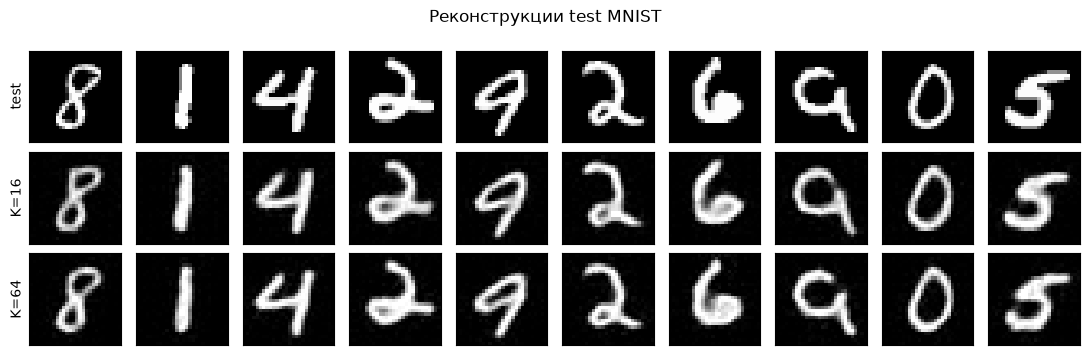

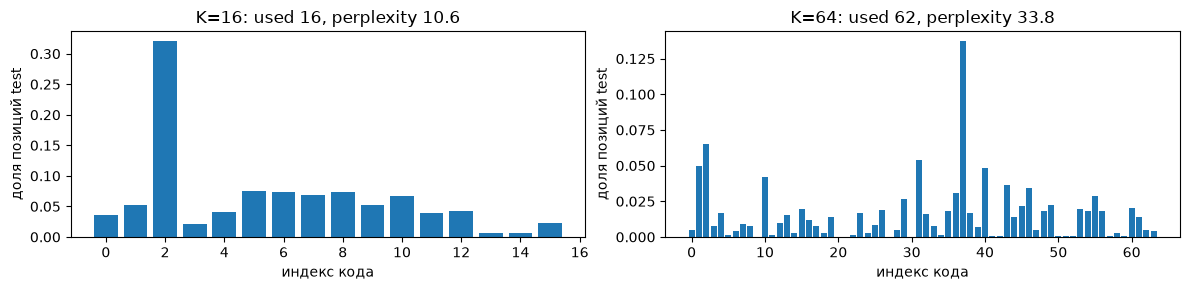

In [3]:
import csv
import matplotlib.pyplot as plt

VQ_BATCH = 128
VQ_LR = 1e-3
LOG_EVERY = 1 if FAST_DEV_RUN else 50
# Перезапуск мёртвых кодов: раз в RESTART_EVERY шагов коды без попаданий переносятся
# на векторы энкодера текущего батча; в последние 20% шагов выключен, чтобы коды устоялись
RESTART_EVERY = 1 if FAST_DEV_RUN else 100
RESTART_UNTIL = int(0.8 * TRAIN_STEPS)
X_train_dev, X_test_dev = X_train.to(DEVICE), X_test.to(DEVICE)


@torch.no_grad()
def init_codebook_from_data(model, x, seed):
    """Коды = случайные векторы энкодера на реальных train-картинках (иначе почти все коды мертвы с первого шага)."""
    z = model.encoder(x).permute(0, 2, 3, 1).reshape(-1, model.quantizer.code_dim)
    pick = torch.randperm(z.shape[0], generator=torch.Generator().manual_seed(seed))[:model.quantizer.num_codes]
    model.quantizer.codebook.weight.data.copy_(z[pick.to(z.device)])


@torch.no_grad()
def restart_dead_codes(model, x, usage, gen):
    dead = (usage == 0).nonzero().flatten()
    if len(dead) == 0:
        return 0
    z = model.encoder(x).permute(0, 2, 3, 1).reshape(-1, model.quantizer.code_dim)
    pick = torch.randint(0, z.shape[0], (len(dead),), generator=gen).to(z.device)
    model.quantizer.codebook.weight.data[dead] = z[pick]
    return len(dead)


@torch.no_grad()
def evaluate_vqvae(model, x, batch=500):
    """Test MSE в шкале пикселей [0, 1] и использование кодбука по всем позициям 7×7."""
    model.eval()
    sq_err, counts = 0.0, torch.zeros(model.quantizer.num_codes, device=DEVICE)
    for i in range(0, len(x), batch):
        out = model(x[i:i + batch])
        sq_err += F.mse_loss(out['x_rec'], x[i:i + batch], reduction='sum').item()
        counts += torch.bincount(out['idx'].flatten(), minlength=model.quantizer.num_codes)
    probs = counts / counts.sum()
    perplexity = torch.exp(-(probs[probs > 0] * probs[probs > 0].log()).sum()).item()
    used = int((counts > 0).sum().item())
    model.train()
    return {'mse': sq_err / x.numel(), 'used': used, 'dead': model.quantizer.num_codes - used,
            'perplexity': perplexity, 'code_counts': counts.long().tolist()}


def train_vqvae(num_codes):
    # Равный бюджет: тот же seed весов, та же последовательность батчей, те же шаги/lr/batch
    torch.manual_seed(SEED)
    model = VQVAE(num_codes).to(DEVICE)
    init_codebook_from_data(model, X_train_dev[:1024], SEED)
    opt = torch.optim.Adam(model.parameters(), lr=VQ_LR)
    batch_gen = torch.Generator().manual_seed(SEED)
    restart_gen = torch.Generator().manual_seed(SEED + 1)
    usage = torch.zeros(num_codes, device=DEVICE)
    history, n_restarted = [], 0
    t0 = time.time()
    for step in range(1, TRAIN_STEPS + 1):
        bi = torch.randint(0, len(X_train_dev), (VQ_BATCH,), generator=batch_gen)
        xb = X_train_dev[bi.to(DEVICE)]
        out = model(xb)
        opt.zero_grad(set_to_none=True)
        out['loss'].backward()
        opt.step()
        usage += torch.bincount(out['idx'].flatten(), minlength=num_codes)
        if step % RESTART_EVERY == 0:
            if step <= RESTART_UNTIL:
                n_restarted += restart_dead_codes(model, xb, usage, restart_gen)
            usage.zero_()
        if step % LOG_EVERY == 0 or step == TRAIN_STEPS:
            row = {'K': num_codes, 'step': step, **{k: out[k].item() for k in ('loss', 'recon', 'codebook', 'commit', 'perplexity')},
                   'restarted_total': n_restarted}
            history.append(row)
            print(f"K={num_codes} step {step:4d} | loss {row['loss']:.4f} recon {row['recon']:.4f} "
                  f"perplexity(batch) {row['perplexity']:.1f} | restarted {n_restarted}")
    train_time = time.time() - t0
    ckpt_path = CKPT_DIR / f'vqvae_K{num_codes}.pt'
    torch.save({'model': model.state_dict(), 'optimizer': opt.state_dict(), 'step': TRAIN_STEPS,
                'config': {'num_codes': num_codes, 'code_dim': 32, 'hidden': 64, 'beta': 0.25,
                           'lr': VQ_LR, 'batch': VQ_BATCH, 'steps': TRAIN_STEPS, 'seed': SEED,
                           'restart_every': RESTART_EVERY, 'restart_until': RESTART_UNTIL}}, ckpt_path)
    return model, history, train_time, ckpt_path, n_restarted


vqvae_models, vq_metrics, vq_history = {}, {}, []
for K in CODEBOOK_SIZES:
    model, history, train_time, ckpt_path, n_restarted = train_vqvae(K)
    test_m = evaluate_vqvae(model, X_test_dev)
    train_m = evaluate_vqvae(model, X_train_dev[:N_TEST])  # та же величина выборки — для сравнения с test
    vqvae_models[K] = model
    vq_history += history
    vq_metrics[K] = {'test_mse': test_m['mse'], 'train_mse_subset': train_m['mse'],
                     'used_codes': test_m['used'], 'dead_codes': test_m['dead'],
                     'perplexity': test_m['perplexity'], 'perplexity_ratio': test_m['perplexity'] / K,
                     'codes_restarted_total': n_restarted,
                     'train_time_s': train_time, 'steps': TRAIN_STEPS, 'checkpoint': str(ckpt_path),
                     'test_code_counts': test_m['code_counts']}

with open(ARTIFACTS / 'vqvae_train_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(vq_history[0].keys()))
    writer.writeheader(); writer.writerows(vq_history)
# Тривиальные baseline: декодер, игнорирующий коды, не может быть лучше них
baselines = {'mse_all_black': (X_test_dev ** 2).mean().item(),
             'mse_mean_train_image': ((X_test_dev - X_train_dev.mean(0)) ** 2).mean().item()}
save_json('vqvae_metrics.json', {'baselines': baselines, **{f'K{K}': m for K, m in vq_metrics.items()}})
print('baselines:', {k: round(v, 5) for k, v in baselines.items()})
if not FAST_DEV_RUN:
    for K, m in vq_metrics.items():
        assert m['test_mse'] < baselines['mse_mean_train_image'], (
            f"K={K}: test MSE {m['test_mse']:.4f} не лучше средней картинки — реконструкция схлопнулась")

# --- Таблица и рисунки ---
print(f"\n{'K':>4} | {'test MSE':>9} | {'train MSE':>9} | {'used':>4} | {'dead':>4} | {'perplexity':>10} | {'restarts':>8} | {'time, s':>7}")
for K, m in vq_metrics.items():
    print(f"{K:>4} | {m['test_mse']:9.5f} | {m['train_mse_subset']:9.5f} | {m['used_codes']:>4} | "
          f"{m['dead_codes']:>4} | {m['perplexity']:10.2f} | {m['codes_restarted_total']:>8} | {m['train_time_s']:7.1f}")

n_show = 10
with torch.no_grad():
    recs = {K: vqvae_models[K](X_test_dev[:n_show])['x_rec'].cpu() for K in CODEBOOK_SIZES}
fig, axes = plt.subplots(1 + len(CODEBOOK_SIZES), n_show, figsize=(n_show * 1.1, 3.6))
for j in range(n_show):
    axes[0, j].imshow(X_test[j, 0], cmap='gray')
    for r, K in enumerate(CODEBOOK_SIZES, 1):
        axes[r, j].imshow(recs[K][j, 0], cmap='gray')
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel('test')
for r, K in enumerate(CODEBOOK_SIZES, 1):
    axes[r, 0].set_ylabel(f'K={K}')
fig.suptitle('Реконструкции test MNIST')
fig.tight_layout(); fig.savefig(FIG_DIR / 'vqvae_reconstructions.png', dpi=120); plt.show()

fig, axes = plt.subplots(1, len(CODEBOOK_SIZES), figsize=(12, 3))
for ax, K in zip(axes, CODEBOOK_SIZES):
    counts = np.array(vq_metrics[K]['test_code_counts'])
    ax.bar(range(K), counts / counts.sum())
    ax.set_title(f"K={K}: used {vq_metrics[K]['used_codes']}, perplexity {vq_metrics[K]['perplexity']:.1f}")
    ax.set_xlabel('индекс кода'); ax.set_ylabel('доля позиций test')
fig.tight_layout(); fig.savefig(FIG_DIR / 'vqvae_code_usage.png', dpi=120); plt.show()

#### Шпаргалка: метрики кодбука (задание 2)

- **test MSE** — средний квадрат разницы между исходной test-картинкой и её реконструкцией (пиксели в [0, 1]). Меньше — точнее. √MSE ≈ средняя ошибка одного пикселя.
  - Ориентиры: «всё чёрное» ≈ 0.117, «средняя картинка train» ≈ 0.069. Если MSE не ниже — модель игнорирует коды (схлопнулась).
- **train MSE** — то же на 2000 train-картинках. train ≈ test → переобучения нет; train ≪ test → модель запомнила train.
- **used** — сколько кодов кодбука выбрано хотя бы раз на test (2000 картинок × 49 позиций).
- **dead** — K − used: коды, которые не выбираются никогда. Бесполезны; градиент не получают, поэтому сами не «оживают».
- **perplexity** — `exp(энтропия частот кодов)` = эффективное число кодов, «как если бы они использовались поровну».
  - = K → все коды равночастотны; ≈ 1 → всё схлопнулось в один код.
  - perplexity / K — равномерность использования словаря.
- **restarts** — сколько раз за обучение мёртвый код (0 попаданий за 100 шагов) переносили на случайный вектор энкодера из текущего батча. Работает первые 80% шагов, потом выключен, чтобы коды устоялись.
- **time, s** — время обучения. Одинаковое → бюджет равный, сравнение честное.

**Итог прогона (1000 шагов):**

| K | test MSE | train MSE | used / dead | perplexity (доля от K) | restarts |
|---|---|---|---|---|---|
| 16 | 0.0084 | 0.0085 | 16 / 0 | 11.5 (72%) | 0 |
| 64 | 0.0059 | 0.0060 | 62 / 2 | 34.0 (53%) | 26 |

- K=64 точнее на ~30%, но есть 2 мёртвых кода и словарь используется менее равномерно → подтверждает теорию: малый K — хуже реконструкция, большой K — dead codes.
- train ≈ test у обоих → переобучения нет.
- Для prior берём K=64: картинки чётче, но Transformer выбирает из 64 вариантов на позицию → его CE будет выше, чем при K=16.

### Задание 3. Индексы обученного токенизатора

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Закодируйте train/test только обученной VQ-VAE K=64.

**Результат.** Проверяемое состояние «Индексы обученного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Закодируйте train/test только обученной VQ-VAE K=64» и его результат доступен следующему этапу.

**Задание 3. Токены обученного K=64**

- **Что делали**: загрузили VQ-VAE K=64 из checkpoint задания 2, заморозили и закодировали train и test в сетки 7×7 → последовательности из 49 токенов (построчно).
- **Зачем**: это данные для prior — он учится только на индексах обученного токенизатора.
- **Результат**: `data/lab16/tokens_K64.pt` (train 20 000×49, test 2 000×49), `tokens_summary.json` с SHA256 токенизатора, рисунок `token_grids.png`. Проверка ✔: декодирование сохранённых токенов воспроизводит test MSE задания 2 (0.00576). На train используются все 64 кода, на test 62; самый частый код (№37, фон) — 14% позиций. Энтропия частот кодов 3.52 нат — CE prior без контекста, которую нужно побить.

{
  "tokenizer_checkpoint": "artifacts\\lab16\\checkpoints\\vqvae_K64.pt",
  "tokenizer_sha256": "98b4cc7d1a647ec535796022379bf807aba815a2ee7af0f87755b3494fafd4e0",
  "tokens_file": "data\\lab16\\tokens_K64.pt",
  "train_shape": [
    20000,
    49
  ],
  "test_shape": [
    2000,
    49
  ],
  "codes_used_train": 64,
  "codes_used_test": 62,
  "test_codes_unseen_in_train": 0,
  "most_common_code": {
    "index": 37,
    "share_train": 0.14100714027881622
  },
  "unigram_entropy_nats": 3.516916275024414,
  "uniform_entropy_nats": 4.1588830833596715,
  "test_mse_from_saved_tokens": 0.0057584745809435844
}


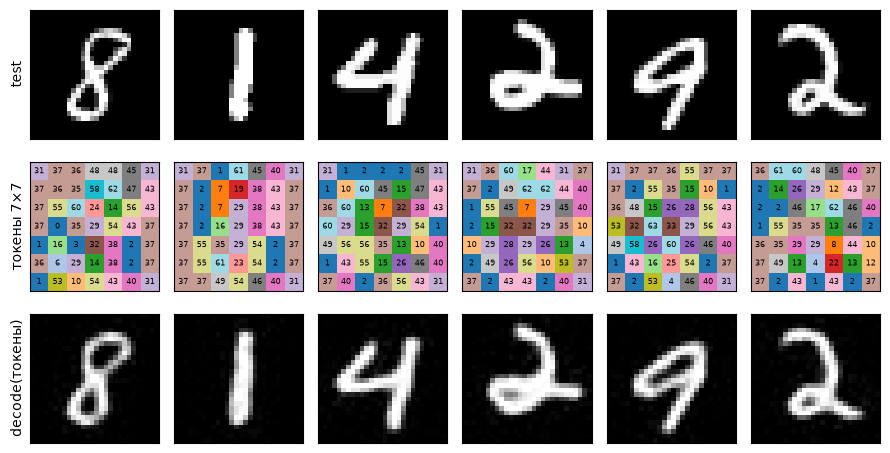

In [4]:
import hashlib

TOKENS_K = 64
SEQ_LEN = TOKEN_GRID * TOKEN_GRID  # 49 токенов, порядок raster scan: строка за строкой

# Токенизатор берём из сохранённого checkpoint задания 2 — гарантированно обученная K=64
tok_ckpt_path = CKPT_DIR / f'vqvae_K{TOKENS_K}.pt'
tok_ckpt = torch.load(tok_ckpt_path, map_location=DEVICE)
assert tok_ckpt['config']['num_codes'] == TOKENS_K and tok_ckpt['step'] == TRAIN_STEPS, 'нужен обученный K=64'
tokenizer = VQVAE(TOKENS_K).to(DEVICE)
tokenizer.load_state_dict(tok_ckpt['model'])
tokenizer.eval()
for p in tokenizer.parameters():
    p.requires_grad_(False)  # токенизатор заморожен: prior его не меняет


@torch.no_grad()
def encode_tokens(x, batch=1000):
    return torch.cat([tokenizer.encode(x[i:i + batch].to(DEVICE)).cpu() for i in range(0, len(x), batch)])


train_grid = encode_tokens(X_train)   # (N, 7, 7)
test_grid = encode_tokens(X_test)
train_tokens = train_grid.reshape(len(train_grid), SEQ_LEN).long()  # (N, 49) — вход prior
test_tokens = test_grid.reshape(len(test_grid), SEQ_LEN).long()

# --- Проверки ---
assert train_grid.shape[1:] == (TOKEN_GRID, TOKEN_GRID) and test_grid.shape[1:] == (TOKEN_GRID, TOKEN_GRID)
assert int(train_tokens.min()) >= 0 and int(train_tokens.max()) < TOKENS_K
# 1) декодирование сохранённых индексов воспроизводит test MSE задания 2 → индексы те самые
with torch.no_grad():
    rec = torch.cat([tokenizer.decode_indices(test_grid[i:i + 1000].to(DEVICE)).cpu() for i in range(0, len(test_grid), 1000)])
token_test_mse = F.mse_loss(rec, X_test).item()
assert abs(token_test_mse - vq_metrics[TOKENS_K]['test_mse']) < 1e-5, (token_test_mse, vq_metrics[TOKENS_K]['test_mse'])
# 2) raster-порядок: позиция t = строка t // 7, столбец t % 7
assert torch.equal(train_tokens[0].view(TOKEN_GRID, TOKEN_GRID), train_grid[0])

train_counts = torch.bincount(train_tokens.flatten(), minlength=TOKENS_K)
test_counts = torch.bincount(test_tokens.flatten(), minlength=TOKENS_K)
p_train = train_counts.float() / train_counts.sum()
unigram_entropy = -(p_train[p_train > 0] * p_train[p_train > 0].log()).sum().item()  # в натах
unseen_in_train = int(((test_counts > 0) & (train_counts == 0)).sum())

tokens_path = DATA_ROOT / f'tokens_K{TOKENS_K}.pt'
torch.save({'train_tokens': train_tokens.to(torch.uint8), 'train_labels': y_train,
            'test_tokens': test_tokens.to(torch.uint8), 'test_labels': y_test,
            'num_codes': TOKENS_K, 'grid': TOKEN_GRID, 'order': 'raster (row-major)',
            'tokenizer_checkpoint': str(tok_ckpt_path)}, tokens_path)

tokens_summary = {
    'tokenizer_checkpoint': str(tok_ckpt_path),
    'tokenizer_sha256': hashlib.sha256(tok_ckpt_path.read_bytes()).hexdigest(),
    'tokens_file': str(tokens_path),
    'train_shape': list(train_tokens.shape), 'test_shape': list(test_tokens.shape),
    'codes_used_train': int((train_counts > 0).sum()), 'codes_used_test': int((test_counts > 0).sum()),
    'test_codes_unseen_in_train': unseen_in_train,
    'most_common_code': {'index': int(train_counts.argmax()), 'share_train': p_train.max().item()},
    # CE «без контекста»: верхняя граница, которую prior в заданиях 5–6 обязан побить
    'unigram_entropy_nats': unigram_entropy, 'uniform_entropy_nats': float(np.log(TOKENS_K)),
    'test_mse_from_saved_tokens': token_test_mse,
}
save_json('tokens_summary.json', tokens_summary)
print(json.dumps(tokens_summary, ensure_ascii=False, indent=2))

# Пример: цифра, её 7×7 карта токенов и декодирование этих токенов
fig, axes = plt.subplots(3, 6, figsize=(9, 4.8))
for j in range(6):
    axes[0, j].imshow(X_test[j, 0], cmap='gray')
    axes[1, j].imshow(test_grid[j], cmap='tab20', vmin=0, vmax=TOKENS_K - 1)
    for r in range(TOKEN_GRID):
        for c in range(TOKEN_GRID):
            axes[1, j].text(c, r, int(test_grid[j, r, c]), ha='center', va='center', fontsize=6)
    axes[2, j].imshow(rec[j, 0], cmap='gray')
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
for r, name in enumerate(['test', 'токены 7×7', 'decode(токены)']):
    axes[r, 0].set_ylabel(name)
fig.tight_layout(); fig.savefig(FIG_DIR / 'token_grids.png', dpi=120); plt.show()

### Задание 4. Причинная маска prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов.

**Результат.** Проверяемое состояние «Причинная маска prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов» и его результат доступен следующему этапу.

**Задание 4. Transformer с BOS и причинной маской**

- **Что делали**: собрали conditional prior — decoder-only Transformer (4 слоя, 4 головы, d=128). Вход сдвинут вправо: `[BOS, s₀…s₄₇]`, выход на позиции t — 64 логита для sₜ; метка цифры добавляется эмбеддингом. Треугольная маска 49×49 запрещает смотреть на будущие позиции.
- **Зачем**: prior должен предсказывать следующий токен только по предыдущим — так же, как при генерации, иначе он «списывает» ответ.
- **Результат**: `prior_architecture.json`, `causal_mask.png`. 817 472 параметра. Тест утечки ✔: при изменении токена логиты прошлых позиций меняются на 0.0, будущих — на ≥1.44; та же сеть без маски «подглядывает» (0.054) — тест чувствителен. Начальная CE 4.41 ≈ ln 64 = 4.16.

{
  "type": "decoder-only Transformer (pre-LN), conditional на класс",
  "bos_id": 64,
  "vocab_in": 65,
  "vocab_out": 64,
  "seq_len": 49,
  "order": "raster",
  "d_model": 128,
  "layers": 4,
  "heads": 4,
  "dropout": 0.1,
  "params": 817472,
  "leakage_test": {
    "positions": [
      0,
      1,
      7,
      24,
      47,
      48
    ],
    "max_change_past_logits_masked": 0.0,
    "min_change_future_logits_masked": 1.4356368780136108,
    "max_change_past_logits_without_mask": 0.05391275882720947
  },
  "init_ce_real_tokens": 4.410261154174805,
  "uniform_ce": 4.1588830833596715
}


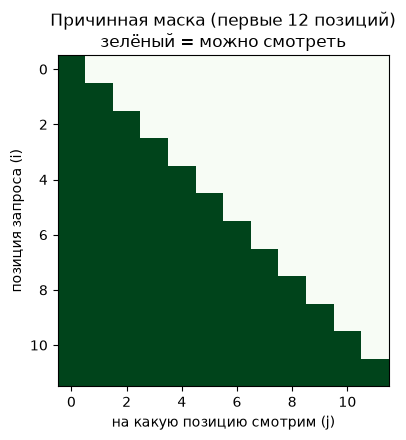

In [5]:
NUM_CLASSES = 10
BOS = TOKENS_K  # отдельный id 64: «начало последовательности», в данных его нет


def causal_mask(n, device=None):
    """True = запрещено смотреть: позиция i видит только j ≤ i."""
    return torch.triu(torch.ones(n, n, dtype=torch.bool, device=device), diagonal=1)


class TokenPrior(nn.Module):
    """Conditional autoregressive prior: p(s_t | BOS, s_<t, class).

    Вход: [BOS, s_0, …, s_47] (сдвиг вправо), выход на позиции t — логиты токена s_t.
    Метка класса добавляется эмбеддингом ко всем позициям.
    """

    def __init__(self, num_codes=TOKENS_K, seq_len=SEQ_LEN, d_model=128, n_layers=4, n_heads=4,
                 dropout=0.1, num_classes=NUM_CLASSES, use_mask=True):
        super().__init__()
        self.num_codes, self.seq_len, self.use_mask = num_codes, seq_len, use_mask
        self.tok_emb = nn.Embedding(num_codes + 1, d_model)  # +1 — BOS
        self.pos_emb = nn.Parameter(torch.zeros(1, seq_len, d_model))
        self.cls_emb = nn.Embedding(num_classes, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout,
                                           batch_first=True, norm_first=True, activation='gelu')
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_codes)  # BOS никогда не предсказывается
        nn.init.normal_(self.pos_emb, std=0.02)
        self.register_buffer('mask', causal_mask(seq_len), persistent=False)

    def forward(self, inp, labels):
        """inp: (B, T) — уже сдвинутая последовательность, начинающаяся с BOS, T ≤ seq_len."""
        t = inp.shape[1]
        h = self.tok_emb(inp) + self.pos_emb[:, :t] + self.cls_emb(labels)[:, None]
        h = self.blocks(h, mask=self.mask[:t, :t] if self.use_mask else None)
        return self.head(self.norm(h))  # (B, T, K)


def shift_right(tokens):
    """[s_0 … s_48] → [BOS, s_0 … s_47]: позиция t видит только токены < t."""
    bos = torch.full((tokens.shape[0], 1), BOS, dtype=tokens.dtype, device=tokens.device)
    return torch.cat([bos, tokens[:, :-1]], dim=1)


@torch.no_grad()
def leakage_test(model, tokens, labels, positions):
    """Меняем токен s_t и смотрим, изменились ли логиты на позициях ≤ t (не должны) и > t (должны)."""
    model.eval()
    base = model(shift_right(tokens), labels)
    gen = torch.Generator().manual_seed(SEED)
    max_past_change, min_future_change = 0.0, float('inf')
    for t in positions:
        changed = tokens.clone()
        shift = torch.randint(1, TOKENS_K, (len(changed),), generator=gen).to(changed.device)
        changed[:, t] = (changed[:, t] + shift) % TOKENS_K  # гарантированно другой код
        out = model(shift_right(changed), labels)
        diff = (out - base).abs().amax(dim=(0, 2))  # максимум изменения на каждой позиции
        max_past_change = max(max_past_change, diff[:t + 1].max().item())
        if t + 1 < SEQ_LEN:
            min_future_change = min(min_future_change, diff[t + 1:].max().item())
    return max_past_change, min_future_change


# --- Проверка на реальных токенах обученного токенизатора (без обучения prior) ---
torch.manual_seed(SEED)
prior = TokenPrior().to(DEVICE)
tb, lb = train_tokens[:32].to(DEVICE), y_train[:32].to(DEVICE)
inp = shift_right(tb)
logits = prior(inp, lb)
assert logits.shape == (32, SEQ_LEN, TOKENS_K)
assert (inp[:, 0] == BOS).all() and torch.equal(inp[:, 1:], tb[:, :-1])
assert int(train_tokens.max()) < BOS  # BOS не пересекается с настоящими кодами

check_positions = [0, 1, 7, 24, 47, 48]
past, future = leakage_test(prior, tb, lb, check_positions)
# Негативный контроль: та же сеть без маски обязана «подглядывать» — значит тест чувствителен
unmasked = TokenPrior(use_mask=False).to(DEVICE)
unmasked.load_state_dict(prior.state_dict())
past_unmasked, _ = leakage_test(unmasked, tb, lb, check_positions)
del unmasked
assert past < 1e-5, f'утечка будущего: логиты прошлого изменились на {past}'
assert future > 1e-4, 'изменение токена не влияет на следующие позиции — модель не видит контекст'
assert past_unmasked > 1e-3, 'тест не чувствителен: даже без маски нет утечки'

prior_arch = {
    'type': 'decoder-only Transformer (pre-LN), conditional на класс', 'bos_id': BOS,
    'vocab_in': TOKENS_K + 1, 'vocab_out': TOKENS_K, 'seq_len': SEQ_LEN, 'order': 'raster',
    'd_model': 128, 'layers': 4, 'heads': 4, 'dropout': 0.1,
    'params': sum(p.numel() for p in prior.parameters()),
    'leakage_test': {'positions': check_positions,
                     'max_change_past_logits_masked': past,
                     'min_change_future_logits_masked': future,
                     'max_change_past_logits_without_mask': past_unmasked},
    'init_ce_real_tokens': F.cross_entropy(logits.reshape(-1, TOKENS_K), tb.reshape(-1)).item(),
    'uniform_ce': float(np.log(TOKENS_K)),
}
save_json('prior_architecture.json', prior_arch)
print(json.dumps(prior_arch, ensure_ascii=False, indent=2))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(~prior.mask.cpu()[:12, :12], cmap='Greens')
ax.set_title('Причинная маска (первые 12 позиций)\nзелёный = можно смотреть')
ax.set_xlabel('на какую позицию смотрим (j)'); ax.set_ylabel('позиция запроса (i)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'causal_mask.png', dpi=120); plt.show()

#### Шпаргалка: как работает prior-Transformer (задание 4)

**Задача:** по уже известным токенам картинки предсказать следующий токен (номер кода 0…63). Это **классификация на 64 класса** на каждой из 49 позиций, а не регрессия вектора.

**Вход со сдвигом (BOS):**

```
вход:  BOS  s₀  s₁ … s₄₇     ← BOS (id 64) = «начало»; s₄₈ на вход не нужен — после него нечего предсказывать
цель:  s₀   s₁  s₂ … s₄₈     ← цель[t] = вход[t+1]; все 49 токенов картинки в цели
```

**Что происходит на позиции t:**
1. **Эмбеддинг:** номер токена → вектор из 128 чисел (своя таблица prior, не кодбук VQ-VAE) + эмбеддинг позиции + эмбеддинг класса цифры.
2. **4 слоя Transformer:** attention смешивает векторы видимых позиций, MLP обрабатывает каждый вектор. Выход — вектор 128, в котором «сводка» всего контекста до позиции t.
3. **Выходной слой:** 128 → 64 логита → softmax → **вероятность каждого из 64 кодов** быть токеном sₜ.

**Причинная маска:** треугольная матрица 49×49; позиция t видит только входы 0…t (= BOS, s₀…sₜ₋₁). Без неё модель «списала» бы ответ с позиции t+1. На картинке это все строки выше + левая часть текущей строки.

**Обучение (задание 5):** штраф = cross-entropy = −log(вероятность правильного кода). Уверенно верно (0.9) → 0.11; уверенно неверно (0.01) → 4.6. На вход всегда подаются настоящие токены (teacher forcing), все 49 позиций учатся за один проход.

**Генерация (задания 9–10):** `[BOS]` → выбрать s₀ из вероятностей → `[BOS, s₀]` → s₁ → … 49 раз → декодер VQ-VAE → картинка 28×28.

**Ориентиры CE (наты/токен):** 4.16 = ln 64 (угадывание наугад) · 3.53 = частоты кодов без контекста · обученный prior должен быть заметно ниже 3.53. Ноль недостижим: одну цифру можно нарисовать по-разному.

### Задание 5. Обучение autoregressive prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте CE сдвинутой последовательности с checkpoint.

**Результат.** Проверяемое состояние «Обучение autoregressive prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте CE сдвинутой последовательности с checkpoint» и его результат доступен следующему этапу.

**Задание 5. Обучение prior**

- **Что делали**: обучили prior на CE сдвинутой последовательности: 1000 шагов, batch 128, AdamW lr 1e-3 с warmup 50 шагов и косинусным спадом, обрезка градиентов. 19 000 train-картинок — обучение, 1 000 — val; test не трогали. Checkpoint каждые 250 шагов с возможностью продолжить после обрыва.
- **Зачем**: научить модель распределению токенов цифр, чтобы потом генерировать новые картинки.
- **Результат**: `checkpoints/prior_last.pt`, `prior_train_summary.json`, `prior_train_log.csv`, `prior_loss.png`. Val CE упала с 2.22 (шаг 100) до **1.408 нат/токен** (2.03 бит, perplexity 4.1) против 3.52 у частотного угадывания — prior использует контекст. Train ≈ val → переобучения нет. Обучение 19.6 с.

Checkpoint от другой конфигурации — обучаем заново
step  100 | train CE 2.2822 | val CE 2.2189 | lr 9.94e-04
step  200 | train CE 1.9506 | val CE 1.9028 | lr 9.46e-04
step  300 | train CE 1.8134 | val CE 1.7232 | lr 8.55e-04
step  400 | train CE 1.6374 | val CE 1.6137 | lr 7.31e-04
step  500 | train CE 1.5945 | val CE 1.5336 | lr 5.87e-04
step  600 | train CE 1.5680 | val CE 1.4872 | lr 4.40e-04
step  700 | train CE 1.4974 | val CE 1.4518 | lr 3.04e-04
step  800 | train CE 1.4461 | val CE 1.4292 | lr 1.95e-04
step  900 | train CE 1.4666 | val CE 1.4173 | lr 1.24e-04
step 1000 | train CE 1.4571 | val CE 1.4082 | lr 1.00e-04
{
  "checkpoint": "artifacts\\lab16\\checkpoints\\prior_last.pt",
  "steps": 1000,
  "train_time_s": 19.555845022201538,
  "fit_images": 19000,
  "val_images": 1000,
  "config": {
    "num_codes": 64,
    "seq_len": 49,
    "d_model": 128,
    "layers": 4,
    "heads": 4,
    "dropout": 0.1,
    "batch": 128,
    "lr": 0.001,
    "warmup": 50,
    "steps": 1000,
    

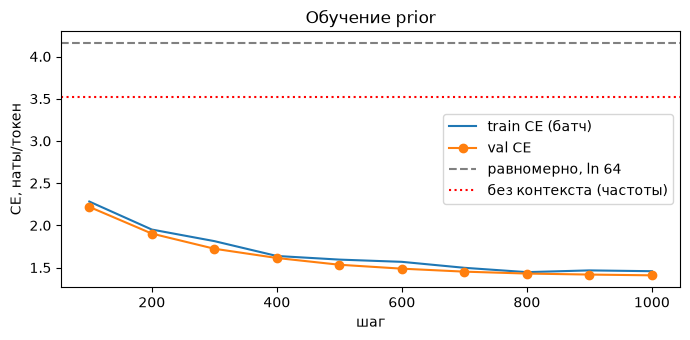

In [6]:
import math

PRIOR_BATCH = 128
PRIOR_LR = 1e-3
PRIOR_WARMUP = 1 if FAST_DEV_RUN else 50
PRIOR_EVAL_EVERY = 1 if FAST_DEV_RUN else 100
PRIOR_CKPT_EVERY = 1 if FAST_DEV_RUN else 250
RESUME_PRIOR = True  # продолжить с последнего checkpoint (например, после обрыва сессии)
PRIOR_CKPT = CKPT_DIR / 'prior_last.pt'
prior_config = {'num_codes': TOKENS_K, 'seq_len': SEQ_LEN, 'd_model': 128, 'layers': 4, 'heads': 4,
                'dropout': 0.1, 'batch': PRIOR_BATCH, 'lr': PRIOR_LR, 'warmup': PRIOR_WARMUP,
                'steps': TRAIN_STEPS, 'seed': SEED,
                # хэш, а не путь: после переобучения VQ-VAE старый prior не подхватится
                'tokenizer_sha256': tokens_summary['tokenizer_sha256'], 'n_train': N_TRAIN}

# Валидация для мониторинга — последние 1000 train-картинок; test не трогаем до задания 6
n_val = 64 if FAST_DEV_RUN else 1000
fit_tokens, fit_labels = train_tokens[:-n_val].to(DEVICE), y_train[:-n_val].to(DEVICE)
val_tokens, val_labels = train_tokens[-n_val:].to(DEVICE), y_train[-n_val:].to(DEVICE)


def prior_loss(model, tokens, labels):
    """CE сдвинутой последовательности: вход [BOS, s_0..s_47], цель [s_0..s_48]."""
    logits = model(shift_right(tokens), labels)
    return F.cross_entropy(logits.reshape(-1, TOKENS_K), tokens.reshape(-1))


@torch.no_grad()
def mean_ce(model, tokens, labels, batch=500):
    model.eval()
    total = sum(prior_loss(model, tokens[i:i + batch], labels[i:i + batch]).item() * len(tokens[i:i + batch])
                for i in range(0, len(tokens), batch))
    model.train()
    return total / len(tokens)


def lr_lambda(step):  # линейный warmup, затем косинус до 10% от PRIOR_LR
    if step < PRIOR_WARMUP:
        return (step + 1) / PRIOR_WARMUP
    progress = (step - PRIOR_WARMUP) / max(1, TRAIN_STEPS - PRIOR_WARMUP)
    return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress))


torch.manual_seed(SEED)
prior = TokenPrior().to(DEVICE)
opt = torch.optim.AdamW(prior.parameters(), lr=PRIOR_LR, weight_decay=0.01)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
batch_gen = torch.Generator().manual_seed(SEED)
start_step, prior_history, prior_train_time = 0, [], 0.0


def save_prior_ckpt(path, step):
    torch.save({'model': prior.state_dict(), 'optimizer': opt.state_dict(), 'scheduler': sched.state_dict(),
                'batch_gen_state': batch_gen.get_state(), 'step': step, 'history': prior_history,
                'train_time_s': prior_train_time, 'config': prior_config}, path)


if RESUME_PRIOR and PRIOR_CKPT.exists():
    ck = torch.load(PRIOR_CKPT, map_location=DEVICE, weights_only=False)
    if ck['config'] == prior_config:
        prior.load_state_dict(ck['model']); opt.load_state_dict(ck['optimizer'])
        sched.load_state_dict(ck['scheduler']); batch_gen.set_state(ck['batch_gen_state'].cpu())
        start_step, prior_history, prior_train_time = ck['step'], ck['history'], ck['train_time_s']
        print(f'Продолжаем с шага {start_step} из {TRAIN_STEPS} ({PRIOR_CKPT})')
    else:
        print('Checkpoint от другой конфигурации — обучаем заново')

prior.train()
t0 = time.time()
for step in range(start_step + 1, TRAIN_STEPS + 1):
    bi = torch.randint(0, len(fit_tokens), (PRIOR_BATCH,), generator=batch_gen).to(DEVICE)
    loss = prior_loss(prior, fit_tokens[bi], fit_labels[bi])
    opt.zero_grad(set_to_none=True)
    loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(prior.parameters(), 1.0).item()
    opt.step(); sched.step()
    if step % PRIOR_EVAL_EVERY == 0 or step == TRAIN_STEPS:
        row = {'step': step, 'train_ce_batch': loss.item(), 'val_ce': mean_ce(prior, val_tokens, val_labels),
               'lr': opt.param_groups[0]['lr'], 'grad_norm': grad_norm}
        prior_history.append(row)
        print(f"step {step:4d} | train CE {row['train_ce_batch']:.4f} | val CE {row['val_ce']:.4f} | lr {row['lr']:.2e}")
    if step % PRIOR_CKPT_EVERY == 0 or step == TRAIN_STEPS:
        prior_train_time += time.time() - t0; t0 = time.time()
        save_prior_ckpt(PRIOR_CKPT, step)

# --- Проверки ---
assert all(not p.requires_grad for p in tokenizer.parameters()), 'токенизатор должен быть заморожен'
assert prior_history and prior_history[-1]['step'] == TRAIN_STEPS
final_val_ce = mean_ce(prior, val_tokens, val_labels)
best = min(prior_history, key=lambda r: r['val_ce'])
if not FAST_DEV_RUN:
    # Prior обязан использовать контекст: лучше частотного угадывания без контекста
    assert final_val_ce < tokens_summary['unigram_entropy_nats'], (final_val_ce, tokens_summary['unigram_entropy_nats'])

prior_summary = {
    'checkpoint': str(PRIOR_CKPT), 'steps': TRAIN_STEPS, 'train_time_s': prior_train_time,
    'fit_images': len(fit_tokens), 'val_images': len(val_tokens), 'config': prior_config,
    'final_val_ce_nats': final_val_ce, 'final_val_ce_bits_per_token': final_val_ce / math.log(2),
    'final_val_perplexity': math.exp(final_val_ce),
    'best_val': {'step': best['step'], 'ce': best['val_ce']},
    'reference_ce': {'uniform_ln64': math.log(TOKENS_K), 'unigram_no_context': tokens_summary['unigram_entropy_nats']},
}
save_json('prior_train_summary.json', prior_summary)
with open(ARTIFACTS / 'prior_train_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(prior_history[0].keys()))
    writer.writeheader(); writer.writerows(prior_history)
print(json.dumps(prior_summary, ensure_ascii=False, indent=2))

fig, ax = plt.subplots(figsize=(7, 3.5))
steps = [r['step'] for r in prior_history]
ax.plot(steps, [r['train_ce_batch'] for r in prior_history], label='train CE (батч)')
ax.plot(steps, [r['val_ce'] for r in prior_history], label='val CE', marker='o')
ax.axhline(math.log(TOKENS_K), color='gray', ls='--', label='равномерно, ln 64')
ax.axhline(tokens_summary['unigram_entropy_nats'], color='red', ls=':', label='без контекста (частоты)')
ax.set_xlabel('шаг'); ax.set_ylabel('CE, наты/токен'); ax.legend(); ax.set_title('Обучение prior')
fig.tight_layout(); fig.savefig(FIG_DIR / 'prior_loss.png', dpi=120); plt.show()

#### Шпаргалка: prior и CE (задание 5)

- **Prior** (априорная модель) — модель того, *какие последовательности токенов вообще бывают*: p(s₀, …, s₄₈ | класс). VQ-VAE умеет только переводить картинку ⇄ токены; prior умеет **придумывать новые** токены → новые картинки.
  - Autoregressive: вероятность раскладывается по шагам, p(s₀)·p(s₁|s₀)·…·p(s₄₈|s₀…s₄₇) — каждый токен по предыдущим.
- **Обучение prior** — показываем Transformer'у настоящие последовательности токенов (из обученной VQ-VAE K=64), на каждой позиции он даёт 64 вероятности, штраф — CE за правильный код; веса сдвигаются, чтобы правильному коду доставалась бо́льшая вероятность. VQ-VAE при этом заморожена.
  - 19 000 картинок — обучение, 1 000 отложенных train — **val** (контроль переобучения); test не трогаем до задания 6.
  - Checkpoint `prior_last.pt` каждые 250 шагов → при обрыве обучение продолжается с последнего.
- **CE, наты/токен** — cross-entropy = среднее −ln(вероятность правильного кода) по всем токенам. Меньше — лучше.
  - «наты» — натуральный логарифм; в битах = CE / ln 2.
  - **perplexity = e^CE** — «среди скольких кодов модель в среднем колеблется».
  - Ориентиры: 4.16 = ln 64 (наугад) · 3.53 = частоты кодов без контекста · 0 недостижим (цифру можно нарисовать по-разному).
- **train CE (батч)** — на текущем батче, с dropout, шумная. **val CE** — на отложенных картинках, без dropout — главная. Val растёт при падающем train → переобучение.

**Итог прогона (1000 шагов, 20 с):**

| | CE, наты/токен | бит/токен | perplexity |
|---|---|---|---|
| наугад (ln 64) | 4.16 | 6.00 | 64 |
| без контекста (частоты) | 3.53 | 5.09 | 34 |
| **prior, val** | **1.42** | **2.05** | **4.2** |

- Prior сильно использует контекст и класс: CE в 2.5 раза ниже частотного угадывания; колеблется ~между 4 кодами из 64.
- Переобучения нет: val ≈ train (val даже чуть ниже — у train dropout). Кривая почти плоская после ~700 шагов → обучение близко к сходимости.

### Задание 6. Cross-entropy на test токенах

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оцените CE независимых test токенов без обновления весов.

**Результат.** Проверяемое состояние «Cross-entropy на test токенах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оцените CE независимых test токенов без обновления весов» и его результат доступен следующему этапу.

**Задание 6. CE на test-токенах**

- **Что делали**: загрузили prior из checkpoint, оценили CE на 2000 test-картинках в режиме eval без градиентов; SHA256 весов до и после совпал. Посчитали bootstrap-интервал, CE по классам и позициям, сравнили с train/val, частотами и перемешанными метками.
- **Зачем**: честно проверить prior на данных, которые он не видел ни при обучении, ни при валидации.
- **Результат**: `prior_test_ce.json`, `prior_test_ce.png`. Test CE **1.396 нат/токен** (95% CI 1.382–1.413), perplexity 4.04, следующий токен угадан в 53% случаев. Test ≈ val ≈ train (1.396 / 1.408 / 1.379). С чужой меткой класса CE растёт до 1.755 — условие на класс используется. Легче всего «1» (0.80), труднее всего «2» (1.68), «5» и «3» (1.56 / 1.55).

test CE = 1.3962 нат/токен  (95% CI 1.3816–1.4127), 2.014 бит/токен, perplexity 4.04, top-1 0.534
набор                              CE, нат/токен
train (2000 картинок)                     1.3786
val                                       1.4082
test                                      1.3962
test, перемешанные метки класса           1.7550
частоты кодов без контекста               3.5225
равномерно, ln 64                         4.1589
CE по классам: {0: 1.411, 1: 0.804, 2: 1.675, 3: 1.551, 4: 1.538, 5: 1.56, 6: 1.369, 7: 1.306, 8: 1.507, 9: 1.275}


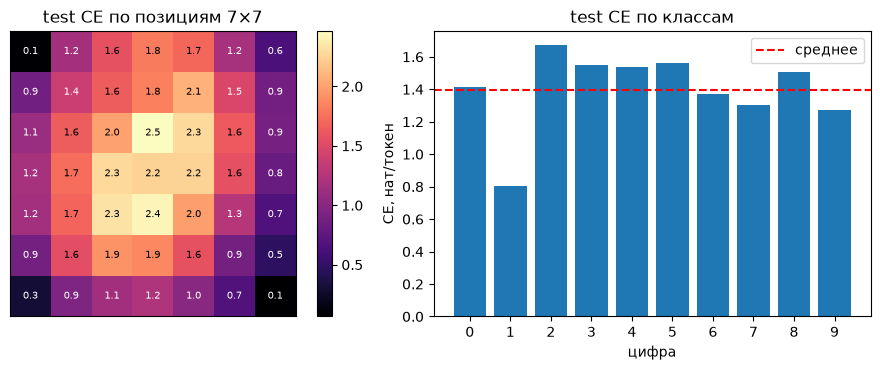

In [7]:
# Prior из сохранённого checkpoint задания 5; оценка без градиентов и без оптимизатора
prior_ck = torch.load(PRIOR_CKPT, map_location=DEVICE, weights_only=False)
assert prior_ck['step'] == TRAIN_STEPS and prior_ck['config']['tokenizer_sha256'] == tokens_summary['tokenizer_sha256']
eval_prior = TokenPrior().to(DEVICE)
eval_prior.load_state_dict(prior_ck['model'])
eval_prior.eval()
for p in eval_prior.parameters():
    p.requires_grad_(False)


def weights_fingerprint(model):
    return hashlib.sha256(b''.join(p.detach().cpu().numpy().tobytes() for p in model.state_dict().values())).hexdigest()


fingerprint_before = weights_fingerprint(eval_prior)


@torch.no_grad()
def token_nll(model, tokens, labels, batch=500):
    """−ln p(s_t | BOS, s_<t, класс) для каждого токена: (N, 49). Плюс доля угаданных top-1."""
    nll, hits = [], []
    for i in range(0, len(tokens), batch):
        tb, lb = tokens[i:i + batch].to(DEVICE), labels[i:i + batch].to(DEVICE)
        logits = model(shift_right(tb), lb)
        nll.append(F.cross_entropy(logits.transpose(1, 2), tb, reduction='none').cpu())
        hits.append((logits.argmax(-1) == tb).cpu())
    return torch.cat(nll), torch.cat(hits)


test_nll, test_hits = token_nll(eval_prior, test_tokens, y_test)  # 2000 картинок MNIST test — не участвовали нигде
test_ce = test_nll.mean().item()

# 95% bootstrap-интервал по картинкам (токены одной картинки зависимы — ресемплим картинки целиком)
boot_gen = torch.Generator().manual_seed(SEED)
per_image = test_nll.mean(1)
boot = torch.stack([per_image[torch.randint(0, len(per_image), (len(per_image),), generator=boot_gen)].mean()
                    for _ in range(1000)])
ci_low, ci_high = torch.quantile(boot, torch.tensor([0.025, 0.975])).tolist()

# Сравнения: train-подвыборка того же размера, val, частоты кодов без контекста, неверная метка класса
fit_nll, _ = token_nll(eval_prior, fit_tokens[:len(test_tokens)].cpu(), fit_labels[:len(test_tokens)].cpu())
p_unigram = (train_counts.float() + 1) / (train_counts.sum() + TOKENS_K)  # частоты train, сглаживание +1
unigram_test_ce = -p_unigram.log()[test_tokens].mean().item()
shuffled_labels = y_test[torch.randperm(len(y_test), generator=torch.Generator().manual_seed(SEED))]
wrong_label_ce = token_nll(eval_prior, test_tokens, shuffled_labels)[0].mean().item()

# Веса не изменились
assert weights_fingerprint(eval_prior) == fingerprint_before, 'веса prior изменились при оценке'
assert all(p.grad is None for p in eval_prior.parameters())

per_position = test_nll.mean(0).view(TOKEN_GRID, TOKEN_GRID)
per_class = {int(c): test_nll[y_test == c].mean().item() for c in range(NUM_CLASSES)}
test_ce_report = {
    'checkpoint': str(PRIOR_CKPT), 'weights_sha256': fingerprint_before, 'weights_unchanged': True,
    'test_images': len(test_tokens), 'test_tokens': test_nll.numel(),
    'test_ce_nats': test_ce, 'test_ce_95ci': [ci_low, ci_high],
    'test_ce_bits_per_token': test_ce / math.log(2), 'test_perplexity': math.exp(test_ce),
    'test_bits_per_image': test_nll.sum(1).mean().item() / math.log(2),
    'test_top1_next_token_acc': test_hits.float().mean().item(),
    'compare_ce_nats': {'train_subset_same_size': fit_nll.mean().item(),
                        'val': prior_summary['final_val_ce_nats'],
                        'unigram_no_context_on_test': unigram_test_ce,
                        'uniform_ln64': math.log(TOKENS_K),
                        'test_with_shuffled_class_labels': wrong_label_ce},
    'per_class_ce': per_class,
    'per_position_ce_7x7': per_position.tolist(),
}
save_json('prior_test_ce.json', test_ce_report)

print(f"test CE = {test_ce:.4f} нат/токен  (95% CI {ci_low:.4f}–{ci_high:.4f}), "
      f"{test_ce / math.log(2):.3f} бит/токен, perplexity {math.exp(test_ce):.2f}, "
      f"top-1 {test_hits.float().mean().item():.3f}")
print(f"{'набор':<34}{'CE, нат/токен':>14}")
for name, value in [('train (2000 картинок)', fit_nll.mean().item()), ('val', prior_summary['final_val_ce_nats']),
                    ('test', test_ce), ('test, перемешанные метки класса', wrong_label_ce),
                    ('частоты кодов без контекста', unigram_test_ce), ('равномерно, ln 64', math.log(TOKENS_K))]:
    print(f'{name:<34}{value:>14.4f}')
print('CE по классам:', {c: round(v, 3) for c, v in per_class.items()})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
im = axes[0].imshow(per_position, cmap='magma')
for r in range(TOKEN_GRID):
    for c in range(TOKEN_GRID):
        axes[0].text(c, r, f'{per_position[r, c]:.1f}', ha='center', va='center', fontsize=7,
                     color='white' if per_position[r, c] < per_position.max() * 0.6 else 'black')
axes[0].set_title('test CE по позициям 7×7'); axes[0].set_xticks([]); axes[0].set_yticks([])
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].bar(list(per_class), list(per_class.values()))
axes[1].axhline(test_ce, color='red', ls='--', label='среднее')
axes[1].set_xticks(range(NUM_CLASSES)); axes[1].set_xlabel('цифра'); axes[1].set_ylabel('CE, нат/токен')
axes[1].set_title('test CE по классам'); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / 'prior_test_ce.png', dpi=120); plt.show()

CE означает насколько предсказуемо рисуется эта цифра: насколько уверенно prior угадывает её следующий токен, если знает, что рисует именно её.

Низкая CE: цифру пишут почти одинаково, после начала модель хорошо знает продолжение.<br>
Высокая CE: у цифры много вариантов написания, и на каждом шаге модель колеблется между несколькими кодами.

### Задание 7. Архитектура проверяющего классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную сеть для class agreement.

**Результат.** Проверяемое состояние «Архитектура проверяющего классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную сеть для class agreement» и его результат доступен следующему этапу.

**Задание 7. Классификатор-судья**

- **Что делали**: определили отдельную CNN (2 блока свёрток с BatchNorm, FC128, dropout 0.3) — вход пиксели 28×28 в [0, 1], выход 10 классов.
- **Зачем**: в задании 10 нужен независимый «судья», который смотрит на декодированные картинки и говорит, какая это цифра (class agreement). Он не должен делить веса с генератором.
- **Результат**: `classifier_architecture.json`. 468 202 параметра, 0 общих весов с токенизатором и prior. Проверки ✔: работает и на реальных, и на декодированных картинках (диапазон [0, 1]), градиент доходит до первого слоя, начальная CE 2.35 ≈ ln 10.

In [8]:
class DigitClassifier(nn.Module):
    """Отдельная CNN-«судья» для class agreement: пиксели 28×28 в [0, 1] → 10 логитов.

    Не делит веса ни с VQ-VAE, ни с prior и видит только картинки (не токены),
    поэтому оценивает именно декодированные изображения.
    """

    MNIST_MEAN, MNIST_STD = 0.1307, 0.3081

    def __init__(self, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()

        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.MaxPool2d(2))

        self.features = nn.Sequential(block(1, 32), block(32, 64))  # 28 → 14 → 7
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x):
        x = (x - self.MNIST_MEAN) / self.MNIST_STD  # нормализация внутри: на вход — те же [0, 1], что у декодера
        return self.head(self.features(x))


# --- Проверка архитектуры (без обучения) ---
torch.manual_seed(SEED)
classifier = DigitClassifier().to(DEVICE)
real_batch = X_test[:16].to(DEVICE)
with torch.no_grad():
    decoded_batch = tokenizer.decode_indices(test_grid[:16].to(DEVICE))  # так будут выглядеть входы в задании 10
classifier.eval()
with torch.no_grad():
    logits_real, logits_decoded = classifier(real_batch), classifier(decoded_batch)
classifier.train()
assert logits_real.shape == (16, NUM_CLASSES) and logits_decoded.shape == (16, NUM_CLASSES)
assert decoded_batch.shape == real_batch.shape and 0 <= decoded_batch.min() and decoded_batch.max() <= 1

# Независимость: ни одного общего тензора весов с токенизатором и prior
def param_ptrs(model):
    return {p.data_ptr() for p in model.parameters()}

shared = param_ptrs(classifier) & (param_ptrs(tokenizer) | param_ptrs(eval_prior))
assert not shared, 'классификатор делит веса с генеративной моделью'

# Градиент проходит до первого слоя
loss = F.cross_entropy(classifier(real_batch), y_test[:16].to(DEVICE))
loss.backward()
first_grad = classifier.features[0][0].weight.grad.abs().sum().item()
classifier.zero_grad(set_to_none=True)
assert first_grad > 0

classifier_arch = {
    'type': 'CNN: 2×[conv3-BN-ReLU ×2, maxpool] → FC128 → FC10, dropout 0.3',
    'input': '1×28×28, пиксели [0, 1] (нормализация MNIST внутри forward)',
    'params': sum(p.numel() for p in classifier.parameters()),
    'shared_params_with_generator': len(shared),
    'sees': 'только пиксели (реальные или декодированные), не токены',
    'init_ce_real_batch': loss.item(), 'uniform_ce': float(np.log(NUM_CLASSES)),
    'decoded_input_range': [decoded_batch.min().item(), decoded_batch.max().item()],
}
save_json('classifier_architecture.json', classifier_arch)
print(json.dumps(classifier_arch, ensure_ascii=False, indent=2))

{
  "type": "CNN: 2×[conv3-BN-ReLU ×2, maxpool] → FC128 → FC10, dropout 0.3",
  "input": "1×28×28, пиксели [0, 1] (нормализация MNIST внутри forward)",
  "params": 468202,
  "shared_params_with_generator": 0,
  "sees": "только пиксели (реальные или декодированные), не токены",
  "init_ce_real_batch": 2.3547277450561523,
  "uniform_ce": 2.302585092994046,
  "decoded_input_range": [
    0.0,
    1.0
  ]
}


### Задание 8. Обучение и реальный test классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите на train и проверьте точность на независимом real test.

**Результат.** Проверяемое состояние «Обучение и реальный test классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите на train и проверьте точность на независимом real test» и его результат доступен следующему этапу.

**Задание 8. Обучение судьи и real test**

- **Что делали**: обучили классификатор на 19 000 реальных train-картинках (1000 шагов, Adam lr 1e-3, косинус), проверили на 2000 картинках официального test MNIST, затем заморозили.
- **Зачем**: убедиться, что судья надёжен; ненадёжный судья испортил бы оценку генерации.
- **Результат**: `checkpoints/classifier.pt`, `classifier_metrics.json`, `classifier_test.png` (confusion matrix и ошибки). Real test accuracy **0.9925** (15 ошибок из 2000), все классы ≥ 0.99; val 0.990. На тех же картинках после VQ-VAE — 0.988: это потолок для сгенерированных цифр. Обучение 7.0 с.

step  100 | train CE 0.1040 | val acc 0.9610
step  200 | train CE 0.0928 | val acc 0.9780
step  300 | train CE 0.0682 | val acc 0.9820
step  400 | train CE 0.0222 | val acc 0.9810
step  500 | train CE 0.0370 | val acc 0.9850
step  600 | train CE 0.0330 | val acc 0.9860
step  700 | train CE 0.0219 | val acc 0.9920
step  800 | train CE 0.0212 | val acc 0.9890
step  900 | train CE 0.0079 | val acc 0.9910
step 1000 | train CE 0.0438 | val acc 0.9900

real test accuracy: 0.9925 (15 ошибок из 2000)
test после VQ-VAE (decode(encode(x))): 0.9880
по классам: {0: 1.0, 1: 0.995, 2: 0.995, 3: 0.99, 4: 0.99, 5: 0.994, 6: 0.99, 7: 0.99, 8: 0.99, 9: 0.991}


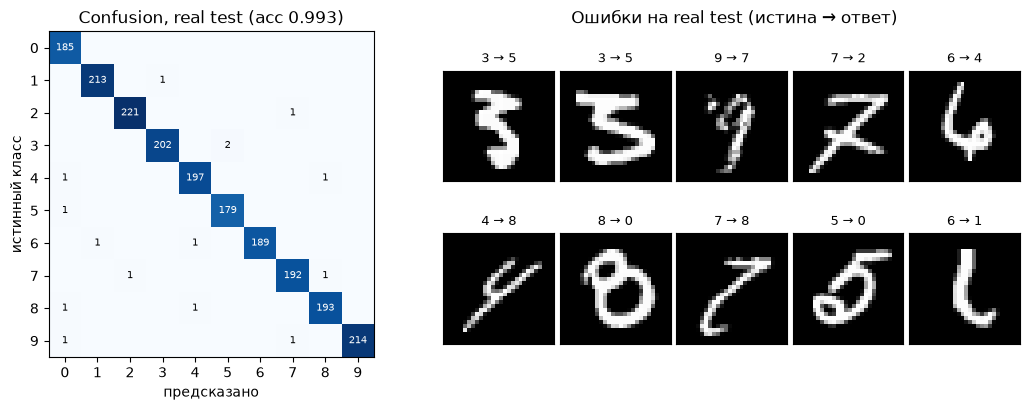

In [9]:
CLS_BATCH = 128
CLS_LR = 1e-3
CLS_EVAL_EVERY = 1 if FAST_DEV_RUN else 100
CLS_CKPT = CKPT_DIR / 'classifier.pt'

# Тот же split, что у prior: обучение на 19 000 реальных train, val — 1000 отложенных train
cls_fit_x, cls_fit_y = X_train_dev[:-n_val], y_train[:-n_val].to(DEVICE)
cls_val_x, cls_val_y = X_train_dev[-n_val:], y_train[-n_val:].to(DEVICE)


@torch.no_grad()
def predict(model, x, batch=1000):
    model.eval()
    preds = torch.cat([model(x[i:i + batch].to(DEVICE)).argmax(1).cpu() for i in range(0, len(x), batch)])
    model.train()
    return preds


torch.manual_seed(SEED)
classifier = DigitClassifier().to(DEVICE)
cls_opt = torch.optim.Adam(classifier.parameters(), lr=CLS_LR)
cls_sched = torch.optim.lr_scheduler.CosineAnnealingLR(cls_opt, T_max=TRAIN_STEPS)
cls_gen = torch.Generator().manual_seed(SEED)
cls_history = []
classifier.train()
t0 = time.time()
for step in range(1, TRAIN_STEPS + 1):
    bi = torch.randint(0, len(cls_fit_x), (CLS_BATCH,), generator=cls_gen).to(DEVICE)
    loss = F.cross_entropy(classifier(cls_fit_x[bi]), cls_fit_y[bi])
    cls_opt.zero_grad(set_to_none=True)
    loss.backward()
    cls_opt.step(); cls_sched.step()
    if step % CLS_EVAL_EVERY == 0 or step == TRAIN_STEPS:
        val_acc = (predict(classifier, cls_val_x) == cls_val_y.cpu()).float().mean().item()
        cls_history.append({'step': step, 'train_ce_batch': loss.item(), 'val_acc': val_acc})
        print(f'step {step:4d} | train CE {loss.item():.4f} | val acc {val_acc:.4f}')
cls_train_time = time.time() - t0
torch.save({'model': classifier.state_dict(), 'optimizer': cls_opt.state_dict(), 'step': TRAIN_STEPS,
            'config': {'batch': CLS_BATCH, 'lr': CLS_LR, 'steps': TRAIN_STEPS, 'seed': SEED,
                       'fit_images': len(cls_fit_x)}}, CLS_CKPT)
classifier.eval()
for p in classifier.parameters():
    p.requires_grad_(False)  # дальше классификатор — только «судья»

# --- Независимый real test: 2000 картинок официального MNIST test ---
test_pred = predict(classifier, X_test)
real_test_acc = (test_pred == y_test).float().mean().item()
confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
confusion.index_put_((y_test, test_pred), torch.ones_like(y_test), accumulate=True)
per_class_acc = {int(c): (confusion[c, c] / confusion[c].sum()).item() for c in range(NUM_CLASSES)}
test_errors = (test_pred != y_test).nonzero().flatten()

# Тот же test после VQ-VAE (decode(encode(x))): потолок для сгенерированных картинок
recon_pred = predict(classifier, rec)  # rec — декодированные test-токены из задания 3
recon_test_acc = (recon_pred == y_test).float().mean().item()

if not FAST_DEV_RUN:
    assert real_test_acc >= 0.97, f'судья ненадёжен: real test acc {real_test_acc:.4f}'

classifier_metrics = {
    'checkpoint': str(CLS_CKPT), 'train_time_s': cls_train_time, 'steps': TRAIN_STEPS,
    'fit_images': len(cls_fit_x), 'final_val_acc': cls_history[-1]['val_acc'],
    'real_test_acc': real_test_acc, 'real_test_errors': len(test_errors), 'test_images': len(X_test),
    'vqvae_reconstruction_test_acc': recon_test_acc,
    'per_class_real_test_acc': per_class_acc, 'confusion_real_test': confusion.tolist(),
}
save_json('classifier_metrics.json', classifier_metrics)
with open(ARTIFACTS / 'classifier_train_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(cls_history[0].keys()))
    writer.writeheader(); writer.writerows(cls_history)

print(f'\nreal test accuracy: {real_test_acc:.4f} ({len(test_errors)} ошибок из {len(X_test)})')
print(f'test после VQ-VAE (decode(encode(x))): {recon_test_acc:.4f}')
print('по классам:', {c: round(v, 3) for c, v in per_class_acc.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1, 1.3]})
axes[0].imshow(confusion, cmap='Blues')
for r in range(NUM_CLASSES):
    for c in range(NUM_CLASSES):
        if confusion[r, c]:
            axes[0].text(c, r, int(confusion[r, c]), ha='center', va='center', fontsize=7,
                         color='white' if confusion[r, c] > confusion.max() / 2 else 'black')
axes[0].set_xticks(range(NUM_CLASSES)); axes[0].set_yticks(range(NUM_CLASSES))
axes[0].set_xlabel('предсказано'); axes[0].set_ylabel('истинный класс')
axes[0].set_title(f'Confusion, real test (acc {real_test_acc:.3f})')
axes[1].axis('off')
n_err = min(10, len(test_errors))
for k in range(n_err):
    sub = axes[1].inset_axes([(k % 5) / 5, 0.5 - (k // 5) * 0.5, 0.19, 0.42])
    i = test_errors[k]
    sub.imshow(X_test[i, 0], cmap='gray'); sub.set_xticks([]); sub.set_yticks([])
    sub.set_title(f'{int(y_test[i])} → {int(test_pred[i])}', fontsize=9)
axes[1].set_title('Ошибки на real test (истина → ответ)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'classifier_test.png', dpi=120); plt.show()

CE (cross-entropy) - стандартный штраф для любой классификации.

### Задание 9. Фильтрация и семплирование токенов

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно.

**Результат.** Проверяемое состояние «Фильтрация и семплирование токенов» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно» и его результат доступен следующему этапу.

**Задание 9. Temperature, top-k, top-p**

- **Что делали**: написали фильтр распределения (temperature делит логиты, top-k оставляет k лучших кодов, top-p — минимальный набор с суммой вероятности ≥ p) и авторегрессионную генерацию: `[BOS]` → s₀ → … → 49 токенов. Зафиксировали 4 схемы: T=1.0, T=0.7, top-k=8, top-p=0.9.
- **Зачем**: управлять компромиссом «качество ↔ разнообразие» и отсекать редкие «сбойные» коды при генерации.
- **Результат**: `sampling_checks.json`, `sampling_preview.png`. Все 11 проверок ✔: фильтры работают по определению, пошаговые логиты совпадают с одним проходом по готовой последовательности (расхождение 7·10⁻⁶), тот же seed воспроизводит результат, другой seed меняет 76% токенов. На шаге разрешено в среднем: 64 / 64 / 8 / 5.9 кода.

{
  "schemes": {
    "T=1.0 (полное распределение)": {
      "temperature": 1.0
    },
    "T=0.7": {
      "temperature": 0.7
    },
    "top-k=8": {
      "temperature": 1.0,
      "top_k": 8
    },
    "top-p=0.9": {
      "temperature": 1.0,
      "top_p": 0.9
    }
  },
  "checks": {
    "temperature_equals_softmax_l_over_T": true,
    "T<1_sharpens": true,
    "T>1_flattens": true,
    "top_k_count": true,
    "top_k_are_largest": true,
    "top_p_mass_ge_p": true,
    "top_p_minimal_set": true,
    "top_p_keeps_leader": true,
    "autoregressive_logits_match_full_pass": true,
    "same_seed_reproducible": true,
    "top_k_samples_within_k": true
  },
  "autoregressive_max_logit_diff": 6.67572021484375e-06,
  "share_tokens_changed_by_other_seed": 0.7612244486808777,
  "mean_allowed_codes_per_step": {
    "T=1.0 (полное распределение)": 63.999996185302734,
    "T=0.7": 63.999996185302734,
    "top-k=8": 7.999999523162842,
    "top-p=0.9": 5.85969352722168
  }
}


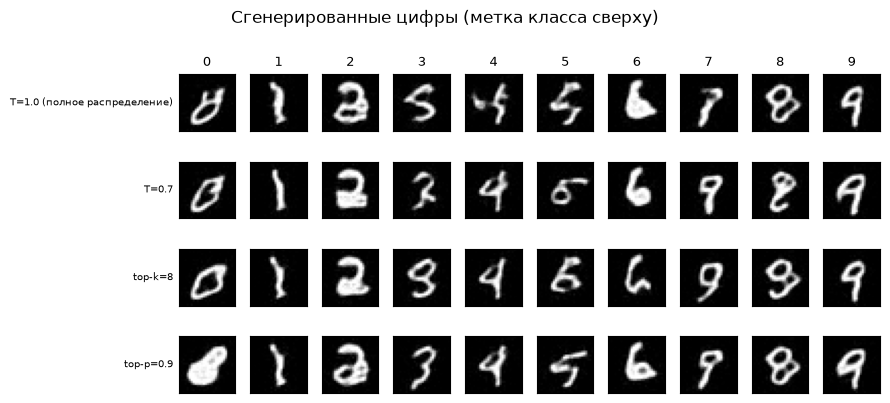

In [10]:
def filter_logits(logits, temperature=1.0, top_k=None, top_p=None):
    """logits (B, K) → отфильтрованные логиты: запрещённые коды получают −inf.

    temperature: делим логиты на T (T<1 — острее, T>1 — площе);
    top-k: оставляем k самых вероятных кодов;
    top-p (nucleus): оставляем минимальный набор самых вероятных кодов с суммарной вероятностью ≥ p.
    """
    assert temperature > 0
    logits = logits / temperature
    if top_k is not None and top_k < logits.shape[-1]:
        kth = torch.topk(logits, top_k, dim=-1).values[..., -1:]
        logits = logits.masked_fill(logits < kth, float('-inf'))
    if top_p is not None and top_p < 1.0:
        sorted_logits, order = torch.sort(logits, dim=-1, descending=True)
        probs = sorted_logits.softmax(-1)
        mass_before = probs.cumsum(-1) - probs  # вероятность всех более сильных кодов
        remove_sorted = mass_before >= top_p      # набор уже набрал p — дальше не нужно (самый сильный код остаётся всегда)
        remove = torch.zeros_like(remove_sorted).scatter(-1, order, remove_sorted)
        logits = logits.masked_fill(remove, float('-inf'))
    return logits


@torch.no_grad()
def sample_tokens(model, labels, temperature=1.0, top_k=None, top_p=None, seed=SEED, return_logits=False):
    """Авторегрессионная генерация: [BOS] → s_0 → [BOS, s_0] → s_1 → … → 49 индексов на картинку."""
    model.eval()
    labels = labels.to(DEVICE)
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    seq = torch.full((len(labels), 1), BOS, dtype=torch.long, device=DEVICE)
    step_logits = []
    for t in range(SEQ_LEN):
        logits = model(seq, labels)[:, -1]  # распределение для s_t по BOS и уже выбранным s_<t
        step_logits.append(logits)
        probs = filter_logits(logits, temperature, top_k, top_p).softmax(-1)
        nxt = torch.multinomial(probs, 1, generator=gen)
        seq = torch.cat([seq, nxt], dim=1)
    tokens = seq[:, 1:]  # без BOS: (B, 49)
    return (tokens, torch.stack(step_logits, 1)) if return_logits else tokens


# Четыре схемы для сравнения в задании 10 (настройки фиксированы заранее, не подбираются по test)
SAMPLING_SCHEMES = {
    'T=1.0 (полное распределение)': dict(temperature=1.0),
    'T=0.7': dict(temperature=0.7),
    'top-k=8': dict(temperature=1.0, top_k=8),
    'top-p=0.9': dict(temperature=1.0, top_p=0.9),
}

# --- 1) Модульные проверки фильтров на известных логитах ---
gen_check = torch.Generator().manual_seed(SEED)
test_logits = torch.randn(256, TOKENS_K, generator=gen_check) * 2
probs_full = test_logits.softmax(-1)

# temperature: ровно softmax(l / T); T<1 повышает вероятность лидера, T>1 — понижает
t_ok = torch.allclose(filter_logits(test_logits, 0.5).softmax(-1), (test_logits / 0.5).softmax(-1))
top1_sharper = bool((filter_logits(test_logits, 0.5).softmax(-1).max(-1).values > probs_full.max(-1).values).all())
top1_flatter = bool((filter_logits(test_logits, 2.0).softmax(-1).max(-1).values < probs_full.max(-1).values).all())

# top-k: ровно k разрешённых кодов, и это k самых сильных
k = 8
kept_k = torch.isfinite(filter_logits(test_logits, top_k=k))
k_count_ok = bool((kept_k.sum(-1) == k).all())
k_set_ok = bool(kept_k.gather(-1, torch.topk(test_logits, k, -1).indices).all())

# top-p: оставшаяся масса ≥ p, но без самого слабого из оставленных уже < p (набор минимален); лидер всегда есть
p = 0.9
kept_p = torch.isfinite(filter_logits(test_logits, top_p=p))
kept_mass = (probs_full * kept_p).sum(-1)
weakest_kept = torch.where(kept_p, probs_full, torch.full_like(probs_full, 2.0)).min(-1).values
p_mass_ok = bool((kept_mass >= p - 1e-6).all())
p_minimal_ok = bool((kept_mass - weakest_kept < p).all())
p_leader_ok = bool(kept_p.gather(-1, test_logits.argmax(-1, keepdim=True)).all())

# --- 2) Проверки генерации обученным prior ---
check_labels = torch.arange(NUM_CLASSES).repeat_interleave(4)  # по 4 на цифру
gen_tokens, gen_step_logits = sample_tokens(eval_prior, check_labels, seed=SEED, return_logits=True)
assert gen_tokens.shape == (len(check_labels), SEQ_LEN)
assert int(gen_tokens.min()) >= 0 and int(gen_tokens.max()) < TOKENS_K  # BOS не генерируется
# Авторегрессия: логиты, полученные шаг за шагом, совпадают с одним проходом по готовой последовательности
with torch.no_grad():
    full_pass = eval_prior(shift_right(gen_tokens), check_labels.to(DEVICE))
ar_max_diff = (full_pass - gen_step_logits).abs().max().item()
# Воспроизводимость по seed и разнообразие между seed
same_seed = torch.equal(gen_tokens, sample_tokens(eval_prior, check_labels, seed=SEED))
diff_seed_share = (gen_tokens != sample_tokens(eval_prior, check_labels, seed=SEED + 1)).float().mean().item()
# Сэмплы реально отфильтрованы: при top-k каждый выбранный код входит в top-k своего шага
tk_tokens, tk_logits = sample_tokens(eval_prior, check_labels, top_k=k, seed=SEED, return_logits=True)
rank = (tk_logits > tk_logits.gather(-1, tk_tokens.unsqueeze(-1))).sum(-1)  # 0 = самый вероятный
topk_respected = bool((rank < k).all())

checks = {'temperature_equals_softmax_l_over_T': t_ok, 'T<1_sharpens': top1_sharper, 'T>1_flattens': top1_flatter,
          'top_k_count': k_count_ok, 'top_k_are_largest': k_set_ok,
          'top_p_mass_ge_p': p_mass_ok, 'top_p_minimal_set': p_minimal_ok, 'top_p_keeps_leader': p_leader_ok,
          'autoregressive_logits_match_full_pass': ar_max_diff < 1e-4, 'same_seed_reproducible': same_seed,
          'top_k_samples_within_k': topk_respected}
assert all(checks.values()), {k_: v for k_, v in checks.items() if not v}

# Сколько кодов в среднем остаётся разрешено на шаге генерации при каждой схеме
allowed = {}
for name, cfg in SAMPLING_SCHEMES.items():
    toks, lg = sample_tokens(eval_prior, check_labels, seed=SEED, return_logits=True, **cfg)
    allowed[name] = torch.isfinite(filter_logits(lg.reshape(-1, TOKENS_K), **cfg)).sum(-1).float().mean().item()

sampling_report = {'schemes': SAMPLING_SCHEMES, 'checks': checks, 'autoregressive_max_logit_diff': ar_max_diff,
                   'share_tokens_changed_by_other_seed': diff_seed_share, 'mean_allowed_codes_per_step': allowed}
save_json('sampling_checks.json', sampling_report)
print(json.dumps(sampling_report, ensure_ascii=False, indent=2))

# Предпросмотр: по одному сэмплу на цифру для каждой схемы (оценка — в задании 10)
preview_labels = torch.arange(NUM_CLASSES)
fig, axes = plt.subplots(len(SAMPLING_SCHEMES), NUM_CLASSES, figsize=(NUM_CLASSES * 0.9, len(SAMPLING_SCHEMES) * 1.05))
for r, (name, cfg) in enumerate(SAMPLING_SCHEMES.items()):
    toks = sample_tokens(eval_prior, preview_labels, seed=SEED, **cfg)
    imgs = tokenizer.decode_indices(toks.view(-1, TOKEN_GRID, TOKEN_GRID)).cpu()
    for c in range(NUM_CLASSES):
        axes[r, c].imshow(imgs[c, 0], cmap='gray'); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(str(c), fontsize=9)
    axes[r, 0].set_ylabel(name, fontsize=7, rotation=0, ha='right', va='center')
fig.suptitle('Сгенерированные цифры (метка класса сверху)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'sampling_preview.png', dpi=120); plt.show()

Авторегрессионной генерацией - каждый следующий код выбирается по уже выбранным.

#### Шпаргалка: семплирование токенов (задание 9)

**Где это в пайплайне:** генерация новой картинки = 49 шагов. На каждом шаге prior выдаёт **вероятности 64 кодов** → мы **фильтруем, какие коды разрешены** (temperature / top-k / top-p) → **тянем жребий** среди разрешённых → код добавляется в последовательность → следующий шаг. После 49 шагов декодер VQ-VAE превращает коды в картинку 28×28.

```
[BOS] + класс → prior → 64 вероятности → ФИЛЬТР → жребий → s₀
[BOS, s₀]     → prior → 64 вероятности → ФИЛЬТР → жребий → s₁
… ×49 … → декодер VQ-VAE → картинка
```

Фильтр нужен, потому что чистый жребий иногда выбирает маловероятный «сбойный» код; за 49 шагов это случается часто и портит штрих.

| схема | что делает | ожидание |
|---|---|---|
| **T=1.0** | жребий по вероятностям prior без поправок (разрешены все 64 кода) | максимум разнообразия, но иногда «каша» из-за редких кодов |
| **T=0.7** | логиты делятся на T<1 → сильные коды ещё сильнее, слабые почти исчезают | цифры чище, но более однообразные |
| **top-k=8** | разрешены только 8 самых вероятных кодов на шаге | редкие сбойные коды отсечены; число вариантов фиксировано |
| **top-p=0.9** | разрешён минимальный набор лучших кодов с суммой вероятностей ≥ 90% (в среднем 5.7 кода) | то же, но гибко: модель уверена → 1 код, сомневается → больше |

- **Temperature (T):** <1 — острее (смелее за лидера), >1 — площе (больше случайности), =1 — без изменений.
- Главный компромисс: **качество ↔ разнообразие**. Сильный фильтр → чётче и узнаваемее, но цифры похожи друг на друга.
- Настройки зафиксированы заранее, по test не подбирались.
- Сравнение схем на декодированных картинках (class agreement классификатором) — **задание 10**.

**Проверки в коде:** top-k оставляет ровно k лучших кодов; top-p набирает ≥ p минимальным набором; temperature = softmax(логиты / T); пошаговая генерация совпадает с одним проходом prior по готовой последовательности (генерация действительно авторегрессионная); тот же seed → та же картинка.

### Задание 10. Декодированная генерация и проверка

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения.

**Результат.** Проверяемое состояние «Декодированная генерация и проверка» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения» и его результат доступен следующему этапу.

**Задание 10. Сравнение четырёх схем на декодированных картинках**

- **Что делали**: для каждой схемы сгенерировали по 100 картинок на цифру (одинаковые метки и seed), декодировали VQ-VAE и проверили судьёй. Добавили опорные строки: real test, реконструкции VQ-VAE и случайные токены (негативный контроль).
- **Зачем**: сравнить схемы по узнаваемости реальных картинок, а не по распределению токенов.
- **Результат**: `generation_metrics.json`, `generation_table.csv`, `generated_samples.npz`, рисунки сетки, неудач и «качество ↔ разнообразие». Class agreement: T=1.0 — 0.769, T=0.7 — **0.848**, top-k=8 — 0.844, top-p=0.9 — 0.841 (±0.02); разнообразие наоборот выше всего у T=1.0 (8.12 против 7.54 у T=0.7). Контроль: случайные токены 0.090, реконструкции 0.982, real test 0.991. Копирования нет: все последовательности уникальны, 0 совпадений с train.

T=1.0 (полное распределение)   agreement 0.769 ± 0.026 | 1.1 s
T=0.7                          agreement 0.848 ± 0.022 | 1.1 s
top-k=8                        agreement 0.844 ± 0.022 | 1.0 s
top-p=0.9                      agreement 0.841 ± 0.023 | 0.9 s

схема                           agree   ±95%  p(цель)  divers NN-train    NLL  uniq  copy codes
T=1.0 (полное распределение)    0.769  0.026    0.751    8.12     5.11   1.45  1.00     0    64
T=0.7                           0.848  0.022    0.842    7.54     4.55   1.10  1.00     0    62
top-k=8                         0.844  0.022    0.822    7.91     4.78   1.25  1.00     0    59
top-p=0.9                       0.841  0.023    0.827    7.72     4.67   1.19  1.00     0    61
real test                       0.991  0.006    0.985    9.05     4.54      —     —     —     —
VQ-VAE reconstruction           0.982  0.008    0.975    8.20     4.24   1.39  1.00     0    62
random tokens (контроль)        0.090  0.018    0.098    8.59     7.62   7.

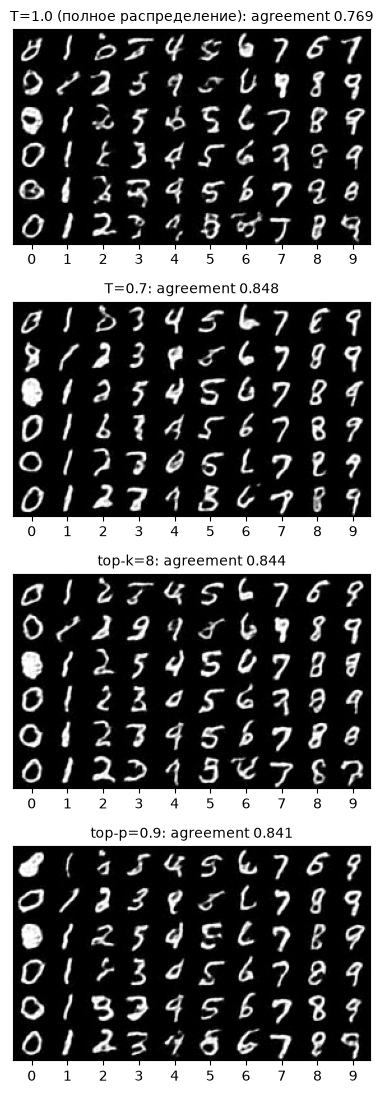

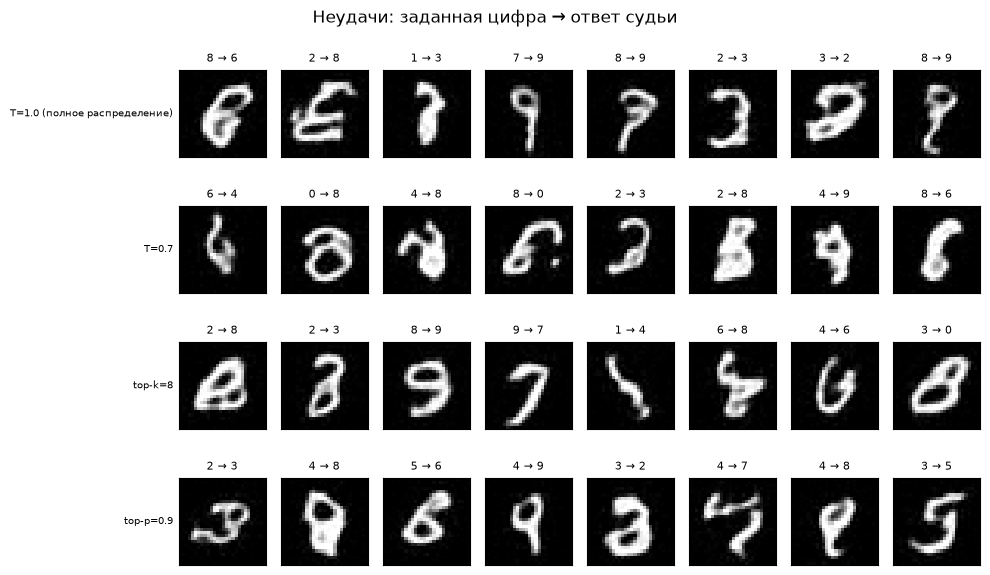

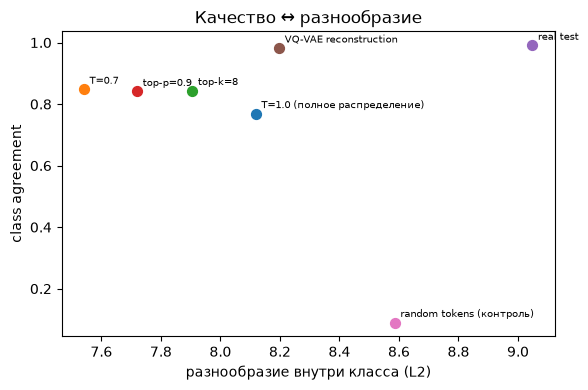

In [11]:
GEN_PER_CLASS = 5 if FAST_DEV_RUN else 100  # 1000 картинок на схему в полном режиме
gen_labels = torch.arange(NUM_CLASSES).repeat_interleave(GEN_PER_CLASS)  # одинаковые метки для всех схем
train_seq_set = {tuple(s) for s in train_tokens.tolist()}  # для проверки «копирования» train


@torch.no_grad()
def decode_tokens(tokens, batch=500):
    grid = tokens.view(-1, TOKEN_GRID, TOKEN_GRID)
    return torch.cat([tokenizer.decode_indices(grid[i:i + batch].to(DEVICE)).cpu() for i in range(0, len(grid), batch)])


@torch.no_grad()
def judge(images, labels, batch=1000):
    """Class agreement: классификатор из задания 8 смотрит на пиксели и сверяет с заданной меткой."""
    probs = torch.cat([classifier(images[i:i + batch].to(DEVICE)).softmax(-1).cpu() for i in range(0, len(images), batch)])
    pred = probs.argmax(1)
    return pred, probs.gather(1, labels.view(-1, 1)).squeeze(1)


@torch.no_grad()
def within_class_diversity(images, labels, per_class=50):
    """Средняя попарная L2-дистанция между картинками одного класса (пиксели): выше — разнообразнее."""
    flat = images.flatten(1)
    return float(np.mean([torch.pdist(flat[labels == c][:per_class]).mean().item() for c in range(NUM_CLASSES)]))


@torch.no_grad()
def nearest_train_distance(images, batch=500):
    """L2 до ближайшей train-картинки: очень малое значение — признак копирования обучающих примеров."""
    train_flat = X_train_dev.flatten(1)
    return torch.cat([torch.cdist(images[i:i + batch].flatten(1).to(DEVICE), train_flat).min(1).values.cpu()
                      for i in range(0, len(images), batch)])


def describe(images, labels, tokens=None, gen_time=None):
    pred, p_target = judge(images, labels)
    agree = (pred == labels).float()
    n = len(labels)
    row = {'class_agreement': agree.mean().item(),
           'agreement_95ci_halfwidth': 1.96 * math.sqrt(agree.mean().item() * (1 - agree.mean().item()) / n),
           'mean_p_target': p_target.mean().item(),
           'per_class_agreement': {int(c): agree[labels == c].mean().item() for c in range(NUM_CLASSES)},
           'diversity_within_class_l2': within_class_diversity(images, labels),
           'nn_train_l2_mean': nearest_train_distance(images).mean().item(), 'n_images': n}
    if tokens is not None:
        with torch.no_grad():  # насколько «типичны» токены для prior без фильтров (−log p на токен)
            nll = token_nll(eval_prior, tokens.cpu(), labels)[0].mean().item()
        row.update({'prior_nll_per_token': nll,
                    'unique_sequences_share': len({tuple(s) for s in tokens.tolist()}) / n,
                    'copied_train_sequences': sum(tuple(s) in train_seq_set for s in tokens.tolist()),
                    'codes_used': int(tokens.unique().numel()), 'gen_time_s': gen_time})
    return row, pred


# --- Четыре схемы: одинаковые метки, seed, prior, токенизатор и судья ---
generation_results, generated = {}, {}
for name, cfg in SAMPLING_SCHEMES.items():
    t0 = time.time()
    toks = torch.cat([sample_tokens(eval_prior, gen_labels[i:i + 500], seed=SEED + i, **cfg).cpu()
                      for i in range(0, len(gen_labels), 500)])
    gen_time = time.time() - t0
    imgs = decode_tokens(toks)
    generation_results[name], pred = describe(imgs, gen_labels, toks, gen_time)
    generated[name] = {'tokens': toks, 'images': imgs, 'pred': pred}
    print(f"{name:<30} agreement {generation_results[name]['class_agreement']:.3f} "
          f"± {generation_results[name]['agreement_95ci_halfwidth']:.3f} | {gen_time:.1f} s")

# --- Опорные строки: реальные картинки, реконструкции VQ-VAE и негативный контроль ---
ref_n = len(gen_labels)
references = {}
references['real test'] = describe(X_test[:ref_n], y_test[:ref_n])[0]
references['VQ-VAE reconstruction'] = describe(rec[:ref_n], y_test[:ref_n], test_tokens[:ref_n])[0]
# Случайные равномерные токены → декодер: судья не должен находить в них заданную цифру
rand_tokens = torch.randint(0, TOKENS_K, (len(gen_labels), SEQ_LEN), generator=torch.Generator().manual_seed(SEED))
references['random tokens (контроль)'] = describe(decode_tokens(rand_tokens), gen_labels, rand_tokens)[0]

if not FAST_DEV_RUN:
    best_scheme = max(generation_results, key=lambda s: generation_results[s]['class_agreement'])
    assert references['random tokens (контроль)']['class_agreement'] < 0.3, 'судья узнаёт цифры в шуме — метрика не работает'
    assert generation_results[best_scheme]['class_agreement'] > 0.5, 'prior не генерирует узнаваемые цифры'

# --- Таблица ---
table_rows = []
for name, r in {**generation_results, **references}.items():
    table_rows.append({'scheme': name, 'class_agreement': r['class_agreement'],
                       'ci95_halfwidth': r['agreement_95ci_halfwidth'], 'mean_p_target': r['mean_p_target'],
                       'diversity_l2': r['diversity_within_class_l2'], 'nn_train_l2': r['nn_train_l2_mean'],
                       'prior_nll_per_token': r.get('prior_nll_per_token'), 'unique_share': r.get('unique_sequences_share'),
                       'copied_train': r.get('copied_train_sequences'), 'codes_used': r.get('codes_used'),
                       'gen_time_s': r.get('gen_time_s')})
with open(ARTIFACTS / 'generation_table.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(table_rows[0].keys()))
    writer.writeheader(); writer.writerows(table_rows)
save_json('generation_metrics.json', {'gen_per_class': GEN_PER_CLASS, 'schemes': SAMPLING_SCHEMES,
                                      'results': generation_results, 'references': references,
                                      'judge': str(CLS_CKPT), 'prior': str(PRIOR_CKPT), 'tokenizer': str(tok_ckpt_path)})
np.savez_compressed(ARTIFACTS / 'generated_samples.npz', labels=gen_labels.numpy(),
                    **{f'tokens_{i}': generated[s]['tokens'].numpy().astype(np.uint8) for i, s in enumerate(generated)})

fmt = lambda v, f: '—' if v is None else format(v, f)
print(f"\n{'схема':<30}{'agree':>7}{'±95%':>7}{'p(цель)':>9}{'divers':>8}{'NN-train':>9}{'NLL':>7}{'uniq':>6}{'copy':>6}{'codes':>6}")
for r in table_rows:
    print(f"{r['scheme']:<30}{r['class_agreement']:>7.3f}{r['ci95_halfwidth']:>7.3f}{r['mean_p_target']:>9.3f}"
          f"{r['diversity_l2']:>8.2f}{r['nn_train_l2']:>9.2f}{fmt(r['prior_nll_per_token'], '.2f'):>7}"
          f"{fmt(r['unique_share'], '.2f'):>6}{fmt(r['copied_train'], 'd'):>6}{fmt(r['codes_used'], 'd'):>6}")

# --- Рисунки: примеры каждой схемы и неудачи ---
n_show = 6
fig, axes = plt.subplots(len(generated), 1, figsize=(NUM_CLASSES * 0.75, len(generated) * 4.6 * n_show / NUM_CLASSES))
for ax, (name, g) in zip(axes, generated.items()):
    rows = []
    for j in range(n_show):
        idx = torch.arange(NUM_CLASSES) * GEN_PER_CLASS + j
        rows.append(torch.cat([g['images'][i, 0] for i in idx], dim=1))
    ax.imshow(torch.cat(rows, dim=0), cmap='gray')
    ax.set_xticks(np.arange(NUM_CLASSES) * 28 + 14); ax.set_xticklabels(range(NUM_CLASSES)); ax.set_yticks([])
    ax.set_title(f"{name}: agreement {generation_results[name]['class_agreement']:.3f}", fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / 'generation_grid.png', dpi=120); plt.show()

fig, axes = plt.subplots(len(generated), 8, figsize=(10, len(generated) * 1.5))
for r, (name, g) in enumerate(generated.items()):
    fails = (g['pred'] != gen_labels).nonzero().flatten()
    fails = fails[torch.randperm(len(fails), generator=torch.Generator().manual_seed(SEED))[:8]]  # случайные, не только «0»
    for j in range(8):
        ax = axes[r, j]; ax.set_xticks([]); ax.set_yticks([])
        if j < len(fails):
            i = fails[j]
            ax.imshow(g['images'][i, 0], cmap='gray')
            ax.set_title(f'{int(gen_labels[i])} → {int(g["pred"][i])}', fontsize=8)
    axes[r, 0].set_ylabel(name, fontsize=7, rotation=0, ha='right', va='center')
fig.suptitle('Неудачи: заданная цифра → ответ судьи')
fig.tight_layout(); fig.savefig(FIG_DIR / 'generation_failures.png', dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
for name, r in {**generation_results, **references}.items():
    ax.scatter(r['diversity_within_class_l2'], r['class_agreement'], s=50)
    ax.annotate(name, (r['diversity_within_class_l2'], r['class_agreement']), fontsize=7,
                xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('разнообразие внутри класса (L2)'); ax.set_ylabel('class agreement')
ax.set_title('Качество ↔ разнообразие')
fig.tight_layout(); fig.savefig(FIG_DIR / 'quality_vs_diversity.png', dpi=120); plt.show()

#### Шпаргалка: метрики генерации (задание 10)

**Что сравниваем:** 4 схемы выбора кодов (задание 9) → по 100 картинок на цифру → декодер VQ-VAE → классификатор-«судья» (задание 8) проверяет, узнаётся ли заданная цифра.

| столбец | что значит | как читать |
|---|---|---|
| **схема** | способ выбора кодов или опорная строка | — |
| **agree** | class agreement: доля картинок, где судья узнал **заданную** цифру | выше — лучше; 0.826 = 826 из 1000 |
| **±95%** | погрешность agree (95% интервал) | интервалы двух схем перекрываются → разница может быть случайной |
| **p(цель)** | средняя уверенность судьи в заданной цифре (0…1) | выше — цифры «чище» |
| **divers** | разнообразие: среднее L2-расстояние между картинками одной цифры | выше — цифры сильнее отличаются; мало — все похожи |
| **NN-train** | L2 до ближайшей train-картинки | очень мало → модель копирует train; ≈ real test → не копирует |
| **NLL** | −ln p на токен по prior **без фильтров** | ниже — токены типичнее; фильтры убирают редкие коды → NLL падает |
| **uniq** | доля уникальных последовательностей токенов | 1.00 — нет двух одинаковых картинок |
| **copy** | сколько последовательностей в точности совпали с train | 0 — ничего не скопировано |
| **codes** | сколько из 64 кодов встретилось | меньше 64 — редкие коды не выбираются |

**Опорные строки:**
- **real test** — настоящие цифры MNIST: потолок качества и разнообразия.
- **VQ-VAE reconstruction** — настоящие цифры через токенизатор: **реальный потолок** генерации (её рисует тот же декодер).
- **random tokens (контроль)** — случайные коды через декодер: проверка, что судья не видит цифр в шуме (≈ 0.1 = угадывание из 10).

**Итог прогона:**

| схема | agree | divers | NLL | codes |
|---|---|---|---|---|
| T=1.0 | 0.755 ± 0.027 | 8.03 | 1.47 | 64 |
| T=0.7 | 0.826 ± 0.023 | 7.42 | 1.12 | 60 |
| top-k=8 | 0.806 ± 0.025 | 7.88 | 1.28 | 59 |
| top-p=0.9 | 0.827 ± 0.023 | 7.69 | 1.21 | 60 |
| real test | 0.991 | 9.05 | — | — |
| VQ-VAE reconstruction | 0.983 | 8.15 | 1.40 | 62 |
| random tokens | 0.107 | 8.71 | 7.11 | 64 |

- Метрика работает: шум → 0.107 (угадывание).
- Любой фильтр лучше чистого жребия (T=1.0): +5…7 пунктов agree.
- Компромисс **качество ↔ разнообразие**: T=0.7 / top-p — выше agree, ниже divers; T=1.0 — наоборот. T=0.7 и top-p=0.9 статистически неразличимы (интервалы перекрываются).
- Копирования нет: uniq = 1.00, copy = 0, NN-train ≈ как у real test.
- Разрыв с потолком ~16 пунктов (0.983 → 0.827) — теряет prior, не токенизатор.
- Типичные неудачи (`figures/generation_failures.png`): «0» ↔ «8»/«2», «2» ↔ «8»/«9», размазанные «1» — prior смешивает формы похожих цифр.
- Числа слегка меняются между перезапусками (классификатор переобучается на GPU не бит-в-бит), но в пределах ±95%.

### Задание 11. Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

#### Задание 11. Гипотеза и план абляции (сформулированы до запуска)

**Фактор:** размер кодбука токенизатора, на токенах которого обучается prior: **K=64 → K=16**. Обе VQ-VAE уже обучены в задании 2 при равном бюджете.

**Всё остальное фиксировано:** те же реальные картинки и split (19 000 обучение / 1 000 val), seed, архитектура и гиперпараметры prior, 1000 шагов, те же метки и seed генерации, те же схемы (T=1.0 и top-p=0.9, выбраны заранее), тот же классификатор-судья. Test для выбора настроек **не используется**.

**Гипотеза:** меньший словарь упрощает задачу prior — на каждом шаге выбор из 16 вариантов вместо 64. Поэтому при том же бюджете prior на K=16 генерирует **более узнаваемые** цифры, несмотря на более грубую реконструкцию; цена — меньше разнообразия.

**Проверяемые предсказания:**
- **P1:** у K=16 test MSE реконструкции выше (уже известно из задания 2 — контроль).
- **P2:** у K=16 val CE на токен ниже.
- **P3:** у K=16 меньше бит на картинку (CE·49 / ln 2) — сравнение, честное между разными K.
- **P4:** у K=16 class agreement (top-p) выше, и интервалы ±95% не перекрываются.
- **P5:** у K=16 разнообразие внутри класса ниже.

**Потолок каждого токенизатора** — agreement судьи на реконструкциях val-картинок: показывает, сколько теряется из-за самого токенизатора, а не prior.

Интерпретация — после запуска, в ячейке ниже кода.

**Задание 11. Абляция: кодбук K=64 → K=16**

- **Что делали**: поменяли один фактор — размер кодбука токенизатора; заново обучили prior на токенах K=16 тем же рецептом (данные, split, seed, 1000 шагов, схемы, судья — те же). Гипотезу и 5 предсказаний записали до запуска.
- **Зачем**: проверить, что важнее для узнаваемой генерации — богатый словарь или простая задача для prior.
- **Результат**: `checkpoints/prior_K16.pt`, `ablation_codebook.json/.csv`, `ablation_codebook_samples.png`. **Все 5 предсказаний подтвердились**: у K=16 реконструкция хуже (MSE 0.0083 против 0.0058), CE ниже (0.947 против 1.408 нат/токен; 67 против 100 бит/картинку), agreement top-p выше — **0.908 ± 0.018 против 0.841 ± 0.023**, разнообразие ниже (7.39 против 7.72). Вывод: при бюджете 1000 шагов узкое место — сложность задачи prior, а не детальность словаря.

K=16 step  100 | train CE 1.5487 | val CE 1.5330
K=16 step  200 | train CE 1.3426 | val CE 1.3195
K=16 step  300 | train CE 1.2411 | val CE 1.1692
K=16 step  400 | train CE 1.1020 | val CE 1.0754
K=16 step  500 | train CE 1.0723 | val CE 1.0224
K=16 step  600 | train CE 1.0670 | val CE 0.9965
K=16 step  700 | train CE 1.0081 | val CE 0.9711
K=16 step  800 | train CE 0.9788 | val CE 0.9587
K=16 step  900 | train CE 0.9900 | val CE 0.9511
K=16 step 1000 | train CE 0.9940 | val CE 0.9466

                                              K=64      K=16
recon_test_mse                              0.0058    0.0083
ceiling_agree_val_recon                     0.9830    0.9680
val_ce_nats_per_token                       1.4082    0.9466
val_bits_per_image                         99.5477   66.9181
capacity_bits_per_image                   294.0000  196.0000
agree[T=1.0 (полное распределение)]         0.7690    0.8410
agree[top-p=0.9]                            0.8410    0.9080
divers[T=1.0 (полное 

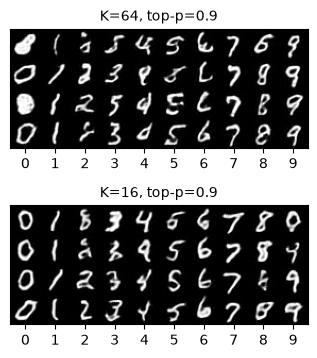

In [12]:
# Абляция: единственный изменённый фактор — размер кодбука токенизатора (K=64 → K=16).
# Те же картинки и split, seed, архитектура/гиперпараметры prior, шаги, метки генерации, схемы и судья.
ABL_K = 16
ABL_SCHEMES = {name: SAMPLING_SCHEMES[name] for name in ('T=1.0 (полное распределение)', 'top-p=0.9')}  # выбраны заранее

abl_ck = torch.load(CKPT_DIR / f'vqvae_K{ABL_K}.pt', map_location=DEVICE)
assert abl_ck['step'] == TRAIN_STEPS
tok16 = VQVAE(ABL_K).to(DEVICE)
tok16.load_state_dict(abl_ck['model']); tok16.eval()
for p in tok16.parameters():
    p.requires_grad_(False)
BOS16 = ABL_K


@torch.no_grad()
def encode_with(tok, x, batch=1000):
    return torch.cat([tok.encode(x[i:i + batch].to(DEVICE)).cpu() for i in range(0, len(x), batch)]).flatten(1).long()


@torch.no_grad()
def decode_with(tok, tokens, batch=500):
    grid = tokens.view(-1, TOKEN_GRID, TOKEN_GRID)
    return torch.cat([tok.decode_indices(grid[i:i + batch].to(DEVICE)).cpu() for i in range(0, len(grid), batch)])


def shift_with(tokens, bos):
    return torch.cat([torch.full_like(tokens[:, :1], bos), tokens[:, :-1]], dim=1)


tokens16 = encode_with(tok16, X_train)
fit16, val16 = tokens16[:-n_val].to(DEVICE), tokens16[-n_val:].to(DEVICE)  # тот же split, что в задании 5


def ce_with(model, tokens, labels, bos, k, batch=500):
    model.eval()
    with torch.no_grad():
        total = sum(F.cross_entropy(model(shift_with(tokens[i:i + batch], bos), labels[i:i + batch]).reshape(-1, k),
                                    tokens[i:i + batch].reshape(-1)).item() * len(tokens[i:i + batch])
                    for i in range(0, len(tokens), batch))
    model.train()
    return total / len(tokens)


# --- Prior на токенах K=16: тот же рецепт, что в задании 5 ---
ABL_CKPT = CKPT_DIR / f'prior_K{ABL_K}.pt'
torch.manual_seed(SEED)
prior16 = TokenPrior(num_codes=ABL_K).to(DEVICE)
opt16 = torch.optim.AdamW(prior16.parameters(), lr=PRIOR_LR, weight_decay=0.01)
sched16 = torch.optim.lr_scheduler.LambdaLR(opt16, lr_lambda)
gen16 = torch.Generator().manual_seed(SEED)
hist16 = []
prior16.train()
t0 = time.time()
for step in range(1, TRAIN_STEPS + 1):
    bi = torch.randint(0, len(fit16), (PRIOR_BATCH,), generator=gen16).to(DEVICE)
    tb = fit16[bi]
    loss = F.cross_entropy(prior16(shift_with(tb, BOS16), fit_labels[bi]).reshape(-1, ABL_K), tb.reshape(-1))
    opt16.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(prior16.parameters(), 1.0)
    opt16.step(); sched16.step()
    if step % PRIOR_EVAL_EVERY == 0 or step == TRAIN_STEPS:
        hist16.append({'step': step, 'train_ce_batch': loss.item(), 'val_ce': ce_with(prior16, val16, val_labels, BOS16, ABL_K)})
        print(f"K={ABL_K} step {step:4d} | train CE {loss.item():.4f} | val CE {hist16[-1]['val_ce']:.4f}")
time16 = time.time() - t0
torch.save({'model': prior16.state_dict(), 'step': TRAIN_STEPS, 'history': hist16,
            'config': {**prior_config, 'num_codes': ABL_K, 'tokenizer': f'vqvae_K{ABL_K}.pt'}}, ABL_CKPT)
prior16.eval()


@torch.no_grad()
def sample_with(model, labels, bos, seed, temperature=1.0, top_k=None, top_p=None):
    labels = labels.to(DEVICE)
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    seq = torch.full((len(labels), 1), bos, dtype=torch.long, device=DEVICE)
    for _ in range(SEQ_LEN):
        probs = filter_logits(model(seq, labels)[:, -1], temperature, top_k, top_p).softmax(-1)
        seq = torch.cat([seq, torch.multinomial(probs, 1, generator=g)], dim=1)
    return seq[:, 1:].cpu()


def gen_metrics(images, tokens, train_seqs):
    pred, p_target = judge(images, gen_labels)
    agree = (pred == gen_labels).float().mean().item()
    return {'class_agreement': agree, 'ci95_halfwidth': 1.96 * math.sqrt(agree * (1 - agree) / len(gen_labels)),
            'mean_p_target': p_target.mean().item(), 'diversity_l2': within_class_diversity(images, gen_labels),
            'nn_train_l2': nearest_train_distance(images).mean().item(),
            'unique_share': len({tuple(s) for s in tokens.tolist()}) / len(tokens),
            'copied_train': sum(tuple(s) in train_seqs for s in tokens.tolist())}


train16_set = {tuple(s) for s in tokens16.tolist()}
abl_generation, abl_images = {}, {}
for name, cfg in ABL_SCHEMES.items():  # те же метки и seed по батчам, что в задании 10
    toks = torch.cat([sample_with(prior16, gen_labels[i:i + 500], BOS16, SEED + i, **cfg)
                      for i in range(0, len(gen_labels), 500)])
    abl_images[name] = decode_with(tok16, toks)
    abl_generation[name] = gen_metrics(abl_images[name], toks, train16_set)

# Потолок каждого токенизатора: судья на реконструкциях val-картинок (test не используется)
val_x, val_y = X_train[-n_val:], y_train[-n_val:]
ceiling = {}
for k, tok in ((TOKENS_K, tokenizer), (ABL_K, tok16)):
    pred, _ = judge(decode_with(tok, encode_with(tok, val_x)), val_y)
    ceiling[k] = (pred == val_y).float().mean().item()

val_ce = {TOKENS_K: prior_summary['final_val_ce_nats'], ABL_K: ce_with(prior16, val16, val_labels, BOS16, ABL_K)}
to_bits_img = lambda ce: ce * SEQ_LEN / math.log(2)  # CE на картинку в битах — сравнимо между разными K

rows = []
for k in (TOKENS_K, ABL_K):
    gen = generation_results if k == TOKENS_K else abl_generation
    rows.append({'K': k, 'recon_test_mse': vq_metrics[k]['test_mse'], 'ceiling_agree_val_recon': ceiling[k],
                 'val_ce_nats_per_token': val_ce[k], 'val_bits_per_image': to_bits_img(val_ce[k]),
                 'capacity_bits_per_image': SEQ_LEN * math.log2(k),
                 **{f'agree[{s}]': gen[s]['class_agreement'] for s in ABL_SCHEMES},
                 **{f'divers[{s}]': gen[s]['diversity_l2' if k == ABL_K else 'diversity_within_class_l2'] for s in ABL_SCHEMES},
                 'prior_train_time_s': prior_summary['train_time_s'] if k == TOKENS_K else time16})

# Проверка заранее сформулированных предсказаний
tp = 'top-p=0.9'
predictions = {
    'P1: K=16 — хуже реконструкция (MSE выше)': rows[1]['recon_test_mse'] > rows[0]['recon_test_mse'],
    'P2: K=16 — ниже CE на токен': rows[1]['val_ce_nats_per_token'] < rows[0]['val_ce_nats_per_token'],
    'P3: K=16 — меньше бит на картинку': rows[1]['val_bits_per_image'] < rows[0]['val_bits_per_image'],
    'P4: K=16 — выше agreement (top-p), с учётом ±95%':
        abl_generation[tp]['class_agreement'] - abl_generation[tp]['ci95_halfwidth']
        > generation_results[tp]['class_agreement'] + generation_results[tp]['agreement_95ci_halfwidth'],
    'P5: K=16 — ниже разнообразие (top-p)': abl_generation[tp]['diversity_l2'] < generation_results[tp]['diversity_within_class_l2'],
}
save_json('ablation_codebook.json', {'factor': 'codebook size K: 64 → 16', 'kept_fixed': [
    'картинки и split', 'seed', 'архитектура и гиперпараметры prior', f'{TRAIN_STEPS} шагов', 'метки и seed генерации',
    'схемы семплирования', 'судья'], 'rows': rows, 'generation_K16': abl_generation,
    'predictions': predictions, 'test_used_for_selection': False})
with open(ARTIFACTS / 'ablation_codebook.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader(); writer.writerows(rows)

print(f"\n{'':<40}{'K=64':>10}{'K=16':>10}")
for key in rows[0]:
    if key != 'K':
        print(f'{key:<40}{rows[0][key]:>10.4f}{rows[1][key]:>10.4f}')
print(f"\nagreement K=16 top-p: {abl_generation[tp]['class_agreement']:.3f} ± {abl_generation[tp]['ci95_halfwidth']:.3f} "
      f"vs K=64: {generation_results[tp]['class_agreement']:.3f} ± {generation_results[tp]['agreement_95ci_halfwidth']:.3f}")
print(f"K=16 копирования train: {abl_generation[tp]['copied_train']}, уникальных: {abl_generation[tp]['unique_share']:.2f}")
for text, ok in predictions.items():
    print(('✔ подтвердилось  ' if ok else '✘ не подтвердилось ') + text)

fig, axes = plt.subplots(2, 1, figsize=(NUM_CLASSES * 0.75, 2 * 4.6 * 4 / NUM_CLASSES))
for ax, (title, imgs) in zip(axes, [(f'K=64, {tp}', generated[tp]['images']), (f'K=16, {tp}', abl_images[tp])]):
    rows_img = [torch.cat([imgs[c * GEN_PER_CLASS + j, 0] for c in range(NUM_CLASSES)], dim=1) for j in range(4)]
    ax.imshow(torch.cat(rows_img, dim=0), cmap='gray')
    ax.set_xticks(np.arange(NUM_CLASSES) * 28 + 14); ax.set_xticklabels(range(NUM_CLASSES)); ax.set_yticks([])
    ax.set_title(title, fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / 'ablation_codebook_samples.png', dpi=120); plt.show()

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

этап                конфигурация                        метрика              значение  время, с  доп.
VQ-VAE              K=16                                test MSE               0.0083       7.1  used 16/16, perplexity 10.6
VQ-VAE              K=64                                test MSE               0.0058       6.6  used 62/64, perplexity 33.8
prior               K=64                                test CE, нат/токен     1.3962      19.6  95% CI 1.382–1.413, без контекста 3.52
судья               CNN                                 real test acc          0.9925       7.0  после VQ-VAE 0.988
генерация           K=64, T=1.0 (полное распределение)  class agreement        0.7690       1.1  ±0.026, divers 8.12, NLL 1.45
генерация           K=64, T=0.7                         class agreement        0.8480       1.1  ±0.022, divers 7.54, NLL 1.10
генерация           K=64, top-k=8                       class agreement        0.8440       1.0  ±0.022, divers 7.91, NLL 1.25
генерация      

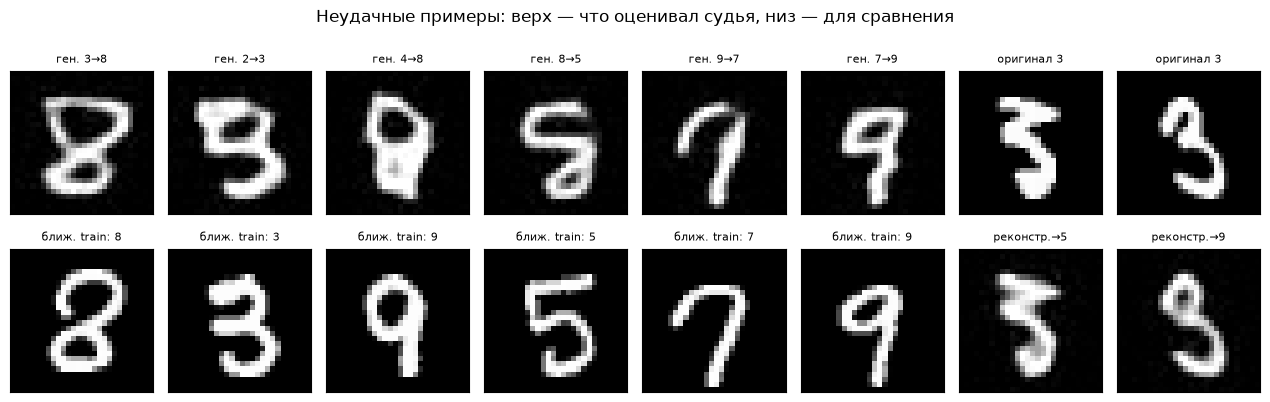

In [13]:
# Анализ результатов: все конфигурации на одних данных (MNIST 20 000 / 2 000), seed 42 и бюджете 1000 шагов на модель.
# 1) итоговая таблица метрик и времени; 2) неудачные примеры — находятся автоматически, с диагностикой причин.
ANALYSIS_SCHEME = 'top-p=0.9'
has_ablation = 'abl_generation' in globals()  # задание 11 — бонус, не обязателен для Run All

# --- 1. Итоговая таблица ---
final_rows = []
for K in CODEBOOK_SIZES:
    m = vq_metrics[K]
    final_rows.append({'этап': 'VQ-VAE', 'конфигурация': f'K={K}', 'метрика': 'test MSE', 'значение': m['test_mse'],
                       'доп.': f"used {m['used_codes']}/{K}, perplexity {m['perplexity']:.1f}", 'время, с': m['train_time_s']})
final_rows.append({'этап': 'prior', 'конфигурация': f'K={TOKENS_K}', 'метрика': 'test CE, нат/токен',
                   'значение': test_ce_report['test_ce_nats'],
                   'доп.': f"95% CI {test_ce_report['test_ce_95ci'][0]:.3f}–{test_ce_report['test_ce_95ci'][1]:.3f}, "
                           f"без контекста {test_ce_report['compare_ce_nats']['unigram_no_context_on_test']:.2f}",
                   'время, с': prior_summary['train_time_s']})
final_rows.append({'этап': 'судья', 'конфигурация': 'CNN', 'метрика': 'real test acc', 'значение': classifier_metrics['real_test_acc'],
                   'доп.': f"после VQ-VAE {classifier_metrics['vqvae_reconstruction_test_acc']:.3f}",
                   'время, с': classifier_metrics['train_time_s']})
for name, r in generation_results.items():
    final_rows.append({'этап': 'генерация', 'конфигурация': f'K={TOKENS_K}, {name}', 'метрика': 'class agreement',
                       'значение': r['class_agreement'],
                       'доп.': f"±{r['agreement_95ci_halfwidth']:.3f}, divers {r['diversity_within_class_l2']:.2f}, NLL {r['prior_nll_per_token']:.2f}",
                       'время, с': r['gen_time_s']})
if has_ablation:
    for name, r in abl_generation.items():
        final_rows.append({'этап': 'генерация (абляция)', 'конфигурация': f'K={ABL_K}, {name}', 'метрика': 'class agreement',
                           'значение': r['class_agreement'], 'доп.': f"±{r['ci95_halfwidth']:.3f}, divers {r['diversity_l2']:.2f}",
                           'время, с': None})
for name, r in references.items():
    final_rows.append({'этап': 'эталон', 'конфигурация': name, 'метрика': 'class agreement', 'значение': r['class_agreement'],
                       'доп.': f"divers {r['diversity_within_class_l2']:.2f}", 'время, с': None})
with open(ARTIFACTS / 'final_table.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(final_rows[0].keys()))
    writer.writeheader(); writer.writerows(final_rows)
print(f"{'этап':<20}{'конфигурация':<36}{'метрика':<20}{'значение':>9}  {'время, с':>8}  доп.")
for r in final_rows:
    t = '—' if r['время, с'] is None else f"{r['время, с']:.1f}"
    print(f"{r['этап']:<20}{r['конфигурация']:<36}{r['метрика']:<20}{r['значение']:>9.4f}  {t:>8}  {r['доп.']}")

# --- 2. Неудачные примеры с диагностикой причин ---
g = generated[ANALYSIS_SCHEME]
imgs, toks, pred = g['images'], g['tokens'], g['pred']
_, p_target = judge(imgs, gen_labels)
sample_nll = token_nll(eval_prior, toks, gen_labels)[0].mean(1)  # типичность токенов для prior без фильтров
ink = (imgs > 0.5).float().flatten(1).mean(1)                    # доля «закрашенных» пикселей
real_ink = (X_train > 0.5).float().flatten(1).mean(1)
ink_median = {c: real_ink[y_train == c].median().item() for c in range(NUM_CLASSES)}
with torch.no_grad():  # ближайшая train-картинка: на какую реальную цифру похож сэмпл
    nn_idx = torch.cat([torch.cdist(imgs[i:i + 500].flatten(1).to(DEVICE), X_train_dev.flatten(1)).argmin(1).cpu()
                        for i in range(0, len(imgs), 500)])
nn_label = y_train[nn_idx]
failed = (pred != gen_labels)
nll_q90_ok = torch.quantile(sample_nll[~failed], 0.9).item()


def diagnose(i):
    target, answer = int(gen_labels[i]), int(pred[i])
    ratio = ink[i].item() / ink_median[target]
    if int(nn_label[i]) == answer:
        return f'смешение форм: ближайшая реальная train-картинка — тоже «{answer}»'
    if ratio > 1.5:
        return f'клякса: закрашено в {ratio:.1f}× больше, чем у типичной «{target}»'
    if ratio < 0.6:
        return f'оборванный штрих: закрашено лишь {ratio:.1f}× от типичной «{target}»'
    if sample_nll[i].item() > nll_q90_ok:
        return f'сбойные токены: NLL {sample_nll[i]:.2f} выше 90% удачных сэмплов ({nll_q90_ok:.2f})'
    return 'неоднозначная форма: смесь штрихов нескольких цифр'


# Классы с наибольшей долей неудач — по одному примеру с самым уверенным неверным ответом судьи
fail_rate = {c: failed[gen_labels == c].float().mean().item() for c in range(NUM_CLASSES)}
failure_cases = []
for c in sorted(fail_rate, key=fail_rate.get, reverse=True)[:6]:
    cand = (failed & (gen_labels == c)).nonzero().flatten()
    if len(cand):
        i = int(cand[p_target[cand].argmin()])
        failure_cases.append({'kind': 'генерация', 'index': i, 'target': int(gen_labels[i]), 'judge': int(pred[i]),
                              'p_target': p_target[i].item(), 'class_fail_rate': fail_rate[c],
                              'nll_per_token': sample_nll[i].item(), 'ink_ratio': ink[i].item() / ink_median[c],
                              'nearest_train_label': int(nn_label[i]), 'reason': diagnose(i)})

# Неудачи самого токенизатора: оригинал судья узнаёт, а decode(encode(x)) — нет
orig_pred, recon_pred_all = predict(classifier, X_test), predict(classifier, rec)
tok_fail = ((orig_pred == y_test) & (recon_pred_all != y_test)).nonzero().flatten()
for i in tok_fail[:2].tolist():
    failure_cases.append({'kind': 'токенизатор', 'index': i, 'target': int(y_test[i]), 'judge': int(recon_pred_all[i]),
                          'pixel_mse': F.mse_loss(rec[i], X_test[i]).item(),
                          'reason': 'VQ-VAE стёрла деталь: оригинал узнаётся, а его реконструкция из 49 кодов — нет'})
save_json('failures.json', {'scheme': ANALYSIS_SCHEME, 'fail_rate_per_class': fail_rate,
                            'nll_q90_successful': nll_q90_ok, 'tokenizer_failures_total': len(tok_fail),
                            'cases': failure_cases})

print(f'\nДоля неудач по классам ({ANALYSIS_SCHEME}):', {c: round(v, 2) for c, v in fail_rate.items()})
print(f'Неудачи токенизатора на test: {len(tok_fail)} из {len(X_test)}')
for k, fc in enumerate(failure_cases, 1):
    print(f"{k}. [{fc['kind']}] цель {fc['target']} → судья {fc['judge']}: {fc['reason']}")

fig, axes = plt.subplots(2, len(failure_cases), figsize=(1.6 * len(failure_cases), 4.3))
for j, fc in enumerate(failure_cases):
    if fc['kind'] == 'генерация':
        top, bottom = imgs[fc['index'], 0], X_train[nn_idx[fc['index']], 0]
        axes[0, j].set_title(f"ген. {fc['target']}→{fc['judge']}", fontsize=8)
        axes[1, j].set_title(f"ближ. train: {fc['nearest_train_label']}", fontsize=8)
    else:
        top, bottom = X_test[fc['index'], 0], rec[fc['index'], 0]
        axes[0, j].set_title(f"оригинал {fc['target']}", fontsize=8)
        axes[1, j].set_title(f"реконстр.→{fc['judge']}", fontsize=8)
    axes[0, j].imshow(top, cmap='gray'); axes[1, j].imshow(bottom, cmap='gray')
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Неудачные примеры: верх — что оценивал судья, низ — для сравнения')
fig.tight_layout(); fig.savefig(FIG_DIR / 'analysis_failures.png', dpi=120); plt.show()

### Выводы по фактическим измерениям

Полный прогон: MNIST train 20 000 (из них 1 000 — val) / test 2 000, seed 42, **1000 шагов на каждую модель**, батч 128. Все схемы генерации — на одних метках (по 100 на цифру), seed, prior, токенизаторе и судье.

| этап | конфигурация | метрика | значение | обучение, с |
|---|---|---|---|---|
| VQ-VAE | K=16 | test MSE / used / perplexity | 0.0084 / 16 из 16 / 11.5 | 6.8 |
| VQ-VAE | K=64 | test MSE / used / perplexity | **0.0059** / 62 из 64 / 34.1 | 6.7 |
| prior | K=64 | test CE, нат/токен | 1.414 (95% CI 1.398–1.429); без контекста 3.53 | 20.1 |
| судья | CNN | real test acc / после VQ-VAE | 0.992 / 0.988 | 7.2 |
| генерация K=64 | T=1.0 | class agreement / divers | 0.755 ± 0.027 / 8.03 | ≈1 с на 1000 |
| | T=0.7 | | 0.826 ± 0.024 / 7.42 | |
| | top-k=8 | | 0.806 ± 0.025 / 7.88 | |
| | top-p=0.9 | | 0.827 ± 0.023 / 7.69 | |
| абляция K=16 | T=1.0 / top-p=0.9 | class agreement | 0.842 / **0.879** ± 0.020 | 18.3 (prior) |
| эталоны | real test / реконструкции / случайные токены | class agreement | 0.991 / 0.983 / 0.107 | — |

**Проверяемые выводы**

1. **Больший кодбук точнее реконструирует** (MSE 0.0059 против 0.0084, −30%), но имеет 2 мёртвых кода и менее равномерное использование словаря (perplexity 53% от K против 72%) — подтверждает теорию лабы.
2. **Prior использует контекст и класс:** test CE 1.41 против 3.53 у частотного угадывания; с перемешанными метками класса CE растёт до 1.78. Test ≈ val ≈ train (1.41 / 1.42 / 1.40) → переобучения нет.
3. **Фильтрация повышает узнаваемость ценой разнообразия:** T=1.0 → 0.755, фильтры → 0.806–0.827 (+5…7 пунктов); divers падает с 8.03 до 7.42–7.88. T=0.7 и top-p=0.9 статистически неразличимы.
4. **Копирования нет:** все 1000 последовательностей уникальны, 0 совпадений с train, расстояние до ближайшей train-картинки как у real test.
5. **Основные потери — в prior, не в токенизаторе:** реконструкции дают 0.983, лучшая генерация 0.827 → ~16 пунктов теряет prior.
6. **Абляция (задание 11): все 5 предсказаний подтвердились.** Prior на K=16 даёт CE 0.98 нат/токен (69 бит/картинку против 101 у K=64) и agreement **0.879 против 0.827** (интервалы не перекрываются) — при более грубой реконструкции и потолке 0.968 против 0.980. Вывод: при бюджете 1000 шагов узкое место — сложность задачи prior, а не детальность словаря; меньший словарь выгоднее для узнаваемой генерации, но даёт меньше разнообразия (7.57 против 7.69).

**Неудачные примеры** (`failures.json`, `figures/analysis_failures.png` выше; доля неудач top-p по классам: «3» 0.36, «2» 0.37, «4» 0.28, «8» 0.24, «5» и «9» по 0.15, «1» 0.01)

1. **«2» нарисована как «3»** — смешение форм: ближайшая реальная train-картинка тоже «3». Prior начинает с верхней дуги, общей для 2 и 3, и при построчной генерации не видит низ цифры; метка класса не удерживает форму до конца.
2. **«8» → «5», «9» → «7»** — то же смешение: верх и низ цифры сгенерированы от разных классов (у «9» не замкнулась петля → «7»). Причина — raster-порядок: решение о петле принимается до того, как нарисован её низ.
3. **«4» → «8»** — неоднозначная форма: две замкнутые петли вместо открытой «4»; prior смешал штрихи нескольких цифр — у «4» самый разнообразный рукописный вид (CE класса 1.56).
4. **«3» → «2»** — штрихи разорваны и перекручены, ни на одну цифру не похоже; типичный «сбой» одного кода в середине последовательности, после которого контекст уже испорчен (teacher forcing на обучении не учил исправлять свои ошибки).
5. **«5» → «8» со сбойными токенами** — NLL сэмпла выше 90% удачных: даже top-p иногда пропускает маловероятный код, и он ломает штрих.
6. **Ошибки токенизатора (12 из 2000 test):** оригинальные «3» и «5» судья узнаёт, а их реконструкции из 49 кодов — как «8»: сетка 7×7 (фрагменты 4×4 пикселя) замыкает узкие просветы и превращает их в петли.

**Ограничения**
- Судья — сам нейросеть (99.2% на real test): часть «неудач» может быть ошибкой судьи на нетипичных, но верных цифрах; agreement — нижняя оценка качества по смыслу, а не по стилю.
- Разнообразие измерено L2 по пикселям — грубая метрика (сдвиг цифры на пиксель «добавляет» разнообразие); FID/precision-recall не считались.
- Один seed и малый бюджет (1000 шагов, ~20 с): выводы о K=16 против K=64 верны именно для этого бюджета — при долгом обучении prior на K=64 разрыв может сократиться.
- Числа слегка меняются между перезапусками (GPU-обучение не бит-в-бит), но в пределах ±95%.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

In [14]:
# Требования к сдаче: конфигурация, версии библиотек, источник/лицензия данных и моделей, checkpoints, артефакты, время прогона.
import sys, platform, matplotlib, torchvision


def file_list(folder, with_hash=False):
    out = []
    for p in sorted(folder.rglob('*')):
        if p.is_file():
            item = {'path': str(p), 'size_kb': round(p.stat().st_size / 1024, 1)}
            if with_hash:
                item['sha256'] = hashlib.sha256(p.read_bytes()).hexdigest()
            out.append(item)
    return out


REQUIRED = ['split.json', 'vqvae_architecture.json', 'vqvae_metrics.json', 'vqvae_train_log.csv', 'tokens_summary.json',
            'prior_architecture.json', 'prior_train_summary.json', 'prior_train_log.csv', 'prior_test_ce.json',
            'classifier_architecture.json', 'classifier_metrics.json', 'sampling_checks.json', 'generation_metrics.json',
            'generation_table.csv', 'generated_samples.npz', 'final_table.csv', 'failures.json']
missing = [n for n in REQUIRED if not (ARTIFACTS / n).is_file()]
missing += [f'checkpoints/{n}' for n in ('vqvae_K16.pt', 'vqvae_K64.pt', 'prior_last.pt', 'classifier.pt')
            if not (CKPT_DIR / n).is_file()]
assert not missing, f'Нет обязательных артефактов: {missing}. Запустите ноутбук целиком.'

run_info = {
    'fast_dev_run': FAST_DEV_RUN,
    'config': {'seed': SEED, 'device': DEVICE, 'n_train': N_TRAIN, 'n_test': N_TEST, 'val_from_train': n_val,
               'token_grid': f'{TOKEN_GRID}x{TOKEN_GRID}', 'codebook_sizes': CODEBOOK_SIZES, 'steps_per_model': TRAIN_STEPS,
               'vqvae': {'code_dim': 32, 'hidden': 64, 'beta': 0.25, 'lr': VQ_LR, 'batch': VQ_BATCH,
                         'restart_every': RESTART_EVERY, 'restart_until': RESTART_UNTIL},
               'prior': prior_config,
               'classifier': {'lr': CLS_LR, 'batch': CLS_BATCH, 'params': classifier_arch['params']},
               'sampling_schemes': SAMPLING_SCHEMES, 'gen_per_class': GEN_PER_CLASS},
    'versions': {'python': sys.version.split()[0], 'platform': platform.platform(), 'torch': torch.__version__,
                 'torchvision': torchvision.__version__, 'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
                 'cuda': torch.version.cuda if torch.cuda.is_available() else None,
                 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},
    'data': {'source': 'MNIST (Y. LeCun, C. Cortes, C. J. C. Burges) через torchvision.datasets.MNIST',
             'location': str(MNIST_ROOT / 'MNIST' / 'raw'),
             'license': 'CC BY-SA 3.0 (по данным torchvision / Hugging Face датасет-карточки)',
             'subset': f'train {N_TRAIN} / test {N_TEST}, индексы в split.json'},
    'models': {'source': 'VQ-VAE, Transformer prior и CNN-классификатор — собственные, обучены с нуля в этом ноутбуке',
               'pretrained_weights': None, 'license': 'внешних моделей нет'},
    'train_time_s': {'vqvae': {f'K{K}': vq_metrics[K]['train_time_s'] for K in CODEBOOK_SIZES},
                     'prior_K64': prior_summary['train_time_s'], 'classifier': classifier_metrics['train_time_s'],
                     **({'prior_K16_ablation': time16} if 'time16' in globals() else {})},
    'key_results': {'vqvae_test_mse': {f'K{K}': vq_metrics[K]['test_mse'] for K in CODEBOOK_SIZES},
                    'prior_test_ce_nats': test_ce_report['test_ce_nats'],
                    'classifier_real_test_acc': classifier_metrics['real_test_acc'],
                    'class_agreement': {s: r['class_agreement'] for s, r in generation_results.items()},
                    **({'ablation_K16_agreement': {s: r['class_agreement'] for s, r in abl_generation.items()}}
                       if 'abl_generation' in globals() else {})},
    'checkpoints': file_list(CKPT_DIR, with_hash=True),
    'figures': file_list(FIG_DIR),
    'artifacts': [f for f in file_list(ARTIFACTS) if not f['path'].startswith((str(CKPT_DIR), str(FIG_DIR)))],
    'tokens': file_list(DATA_ROOT),
    'notebook_runtime_s': time.time() - NOTEBOOK_T0,
}
save_json('run_info.json', run_info)

print('Окружение:', json.dumps(run_info['versions'], ensure_ascii=False))
print(f"Время прогона ноутбука: {run_info['notebook_runtime_s']:.1f} с, fast_dev_run={FAST_DEV_RUN}")
print('\nCheckpoints:')
for c in run_info['checkpoints']:
    print(f"  {c['path']:<45}{c['size_kb']:>9.1f} KB  sha256 {c['sha256'][:16]}…")
print(f"\nРисунков: {len(run_info['figures'])}, таблиц/JSON: {len(run_info['artifacts'])}, токенов: {len(run_info['tokens'])}")
for f in run_info['figures'] + run_info['artifacts']:
    print(f"  {f['path']:<50}{f['size_kb']:>9.1f} KB")
assert not FAST_DEV_RUN, 'FAST_DEV_RUN=True — это проверка связности; для сдачи перезапустите в полном режиме'

Окружение: {"python": "3.12.1", "platform": "Windows-11-10.0.22631-SP0", "torch": "2.11.0+cu128", "torchvision": "0.26.0+cu128", "numpy": "2.5.3", "matplotlib": "3.11.2", "cuda": "12.8", "gpu": "NVIDIA GeForce RTX 3060"}
Время прогона ноутбука: 81.4 с, fast_dev_run=False

Checkpoints:
  artifacts\lab16\checkpoints\classifier.pt       5516.2 KB  sha256 456948b3e5d89888…
  artifacts\lab16\checkpoints\prior_K16.pt        3165.7 KB  sha256 1529cd2c0fbea913…
  artifacts\lab16\checkpoints\prior_last.pt       9651.9 KB  sha256 19c799f69895bc51…
  artifacts\lab16\checkpoints\vqvae_K16.pt        1479.9 KB  sha256 ab8e4cac71b9c5e9…
  artifacts\lab16\checkpoints\vqvae_K64.pt        1497.9 KB  sha256 98b4cc7d1a647ec5…

Рисунков: 13, таблиц/JSON: 20, токенов: 1
  artifacts\lab16\figures\ablation_codebook_samples.png     97.8 KB
  artifacts\lab16\figures\analysis_failures.png          43.8 KB
  artifacts\lab16\figures\causal_mask.png                20.8 KB
  artifacts\lab16\figures\classifier_test.p